# Dự đoán sớm suy giảm sức khỏe Edge Node bằng LSTM

**Bài toán.** Từ telemetry 5 phút gần nhất của một node (60 mẫu × 5 s), dự đoán node có chuyển sang
`DEGRADED`/`CRITICAL` trong **10 phút tới** hay không (`future_degradation`, spec §18).

**Feature (MVP node-health tree).**

| Nhóm | Feature |
|---|---|
| Connectivity | `heartbeat_age_sec`, `connection_reconnect_count` |
| Hardware | `cpu_usage_pct`, `memory_usage_pct`, `gpu_usage_pct`, `gpu_temperature_c`, `disk_usage_pct` |
| Runtime | `inference_fps`, `inference_latency_ms`, `runtime_restart_count`, `runtime_error_count` |

**Dữ liệu.** Synthetic, sinh bởi `src.ml.telemetry_sim` (8 kịch bản lỗi + healthy + 2 kịch bản "báo động giả").
Nhãn `state` được suy ra từ chỉ số quan sát được, không từ mức độ lỗi inject.

**Lộ trình.** 1 Setup → 2 Sinh dữ liệu → 3 Load → 4 EDA → 5 Windowing → 6 Baseline → 7 LSTM → 8 Đánh giá test →
9 Phân tích theo kịch bản / lead time / báo động giả → 10 Lưu model → 11 Kết luận.

## 1. Setup

In [1]:
import os, sys, json, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent  # chạy từ app/ hoặc app/notebooks/
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, classification_report)
from sklearn.linear_model import LogisticRegression

from src.ml.telemetry_sim.dataset import FEATURES, COUNTERS, build, episode_matrix

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
DATA = ROOT / "dataset" / "telemetry_sim"
NPZ = DATA / "lstm_w60_h120.npz"
OUT = DATA / "models"; OUT.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
STATE_ORDER = ["NORMAL", "WARNING", "DEGRADED", "CRITICAL"]
BENIGN = ["healthy", "load_burst", "network_blip"]
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("root:", ROOT, "| device:", DEVICE, "| torch", torch.__version__)

root: D:\Workspace\Research\ultralytics\app | device: cpu | torch 2.14.0+cpu


## 2. Sinh dữ liệu (tuỳ chọn)

Dataset đã có sẵn trong `dataset/telemetry_sim/`. Đặt `REGENERATE = True` để sinh lại (≈1–2 phút, CPU).
Seed cố định ⇒ tái lập được.

In [2]:
REGENERATE = False
if REGENERATE or not (DATA / "manifest.csv").exists():
    !python -m src.ml.telemetry_sim generate --out dataset/telemetry_sim --nodes 40 --episodes-per-node 10 --seed 0
    !python -m src.ml.telemetry_sim build --src dataset/telemetry_sim --out dataset/telemetry_sim/lstm_w60_h120.npz

## 3. Load dữ liệu thô

In [3]:
manifest = pd.read_csv(DATA / "manifest.csv")
df = pd.concat([pd.read_csv(p, parse_dates=["timestamp"]) for p in sorted((DATA / "episodes").glob("*.csv.gz"))],
               ignore_index=True)
df["state"] = pd.Categorical(df["state"], STATE_ORDER, ordered=True)
print(f"{len(df):,} dòng | {df.cluster_id.nunique()} cluster | {df.node_id.nunique()} node | "
      f"{df.episode_id.nunique()} episode | {len(df) * 5 / 3600:,.0f} giờ telemetry")
df.head()

550,167 dòng | 4 cluster | 40 node | 400 episode | 764 giờ telemetry


,timestamp,cluster_id,node_id,runtime_id,episode_id,scenario,phase,fault_severity,state,future_degradation,...,connection_reconnect_count,cpu_usage_pct,memory_usage_pct,gpu_usage_pct,gpu_temperature_c,disk_usage_pct,inference_fps,inference_latency_ms,runtime_restart_count,runtime_error_count
0,2026-01-01 00:17:29.459856+00:00,sim-cluster-0,sim-node-000,sim-node-000-rt0,sim-node-000-e000,load_burst,healthy,0.0,NORMAL,0,...,0.0,25.38,61.25,75.57,NaN,52.3,24.20,31.05,0.0,1.0
1,2026-01-01 00:17:34.459856+00:00,sim-cluster-0,sim-node-000,sim-node-000-rt0,sim-node-000-e000,load_burst,healthy,0.0,NORMAL,0,...,0.0,30.01,61.16,70.53,42.50,52.3,25.22,29.86,0.0,0.0
2,2026-01-01 00:17:39.459856+00:00,sim-cluster-0,sim-node-000,sim-node-000-rt0,sim-node-000-e000,load_burst,healthy,0.0,NORMAL,0,...,0.0,30.70,61.38,76.07,42.50,52.3,25.41,30.86,0.0,0.0
3,2026-01-01 00:17:44.459856+00:00,sim-cluster-0,sim-node-000,sim-node-000-rt0,sim-node-000-e000,load_burst,healthy,0.0,NORMAL,0,...,0.0,32.44,61.18,72.81,42.69,52.3,24.64,29.81,0.0,0.0
4,2026-01-01 00:17:49.459856+00:00,sim-cluster-0,sim-node-000,sim-node-000-rt0,sim-node-000-e000,load_burst,healthy,0.0,NORMAL,0,...,0.0,26.99,61.36,75.94,43.09,NaN,25.37,30.20,0.0,0.0


## 4. EDA
### 4.1 Phân bố kịch bản, trạng thái và nhãn

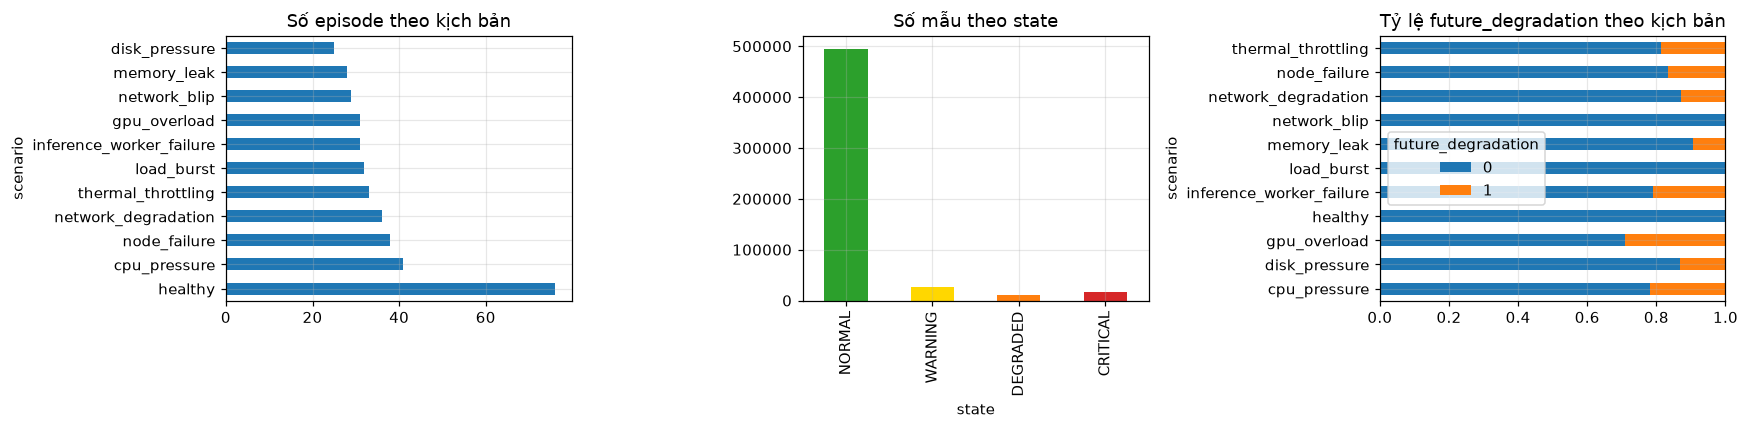

Tỷ lệ dương toàn bộ: 0.1147


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
manifest.scenario.value_counts().plot.barh(ax=ax[0], title="Số episode theo kịch bản")
df.state.value_counts().reindex(STATE_ORDER).plot.bar(ax=ax[1], title="Số mẫu theo state",
                                                      color=["tab:green", "gold", "tab:orange", "tab:red"])
pd.crosstab(df.scenario, df.future_degradation, normalize="index").plot.barh(
    stacked=True, ax=ax[2], title="Tỷ lệ future_degradation theo kịch bản")
plt.tight_layout(); plt.show()
print("Tỷ lệ dương toàn bộ:", round(df.future_degradation.mean(), 4))

**Nhận xét.** Dữ liệu mất cân bằng mạnh (≈ vài % mẫu dương), đúng bản chất bài toán vận hành.
Các kịch bản benign (`healthy`, `load_burst`, `network_blip`) có tỷ lệ dương = 0, dùng để đo báo động giả.

### 4.2 Giá trị thiếu

In [5]:
miss = df[FEATURES].isna().mean().sort_values(ascending=False) * 100
display(miss.to_frame("% missing").T.round(2))
print("Missing do node treo (chỉ còn heartbeat):", int((df.cpu_usage_pct.isna() & df.heartbeat_age_sec.notna()).sum()), "dòng")

,inference_latency_ms,gpu_usage_pct,gpu_temperature_c,memory_usage_pct,runtime_restart_count,connection_reconnect_count,cpu_usage_pct,inference_fps,disk_usage_pct,runtime_error_count,heartbeat_age_sec
% missing,2.64,1.95,1.94,0.95,0.94,0.94,0.94,0.93,0.92,0.54,0.4


Missing do node treo (chỉ còn heartbeat): 5157 dòng


Missing có các nguồn: (1) collector lỗi ngẫu nhiên, (2) GPU message mất, (3) node treo → chỉ còn `heartbeat_age_sec`,
(4) runtime chết → không có latency. Khi windowing ta **forward-fill** (giống giá trị cuối cùng Cloud còn giữ),
phần còn thiếu điền bằng mean của train.

### 4.3 Thống kê mô tả và phân bố theo state

,count,mean,std,min,25%,50%,75%,max
heartbeat_age_sec,547993.0,3.91,19.49,0.01,1.33,2.62,3.92,596.50
connection_reconnect_count,544976.0,2.84,3.70,0.00,1.00,2.00,4.00,53.00
cpu_usage_pct,545002.0,30.17,12.31,0.80,23.96,28.57,33.38,100.00
memory_usage_pct,544924.0,57.99,10.85,40.52,51.18,56.64,62.87,98.50
gpu_usage_pct,539443.0,53.26,20.05,0.00,35.47,58.19,67.98,100.00
gpu_temperature_c,539468.0,57.78,10.05,35.85,52.02,56.95,62.09,148.70
disk_usage_pct,545111.0,50.25,14.84,25.01,38.31,51.41,61.52,99.80
inference_fps,545037.0,18.77,6.03,0.00,14.88,15.07,24.82,31.03
inference_latency_ms,535666.0,30.97,15.98,7.91,21.87,30.42,40.15,240.10
runtime_restart_count,544970.0,1.37,2.47,0.00,0.00,1.00,2.00,30.00


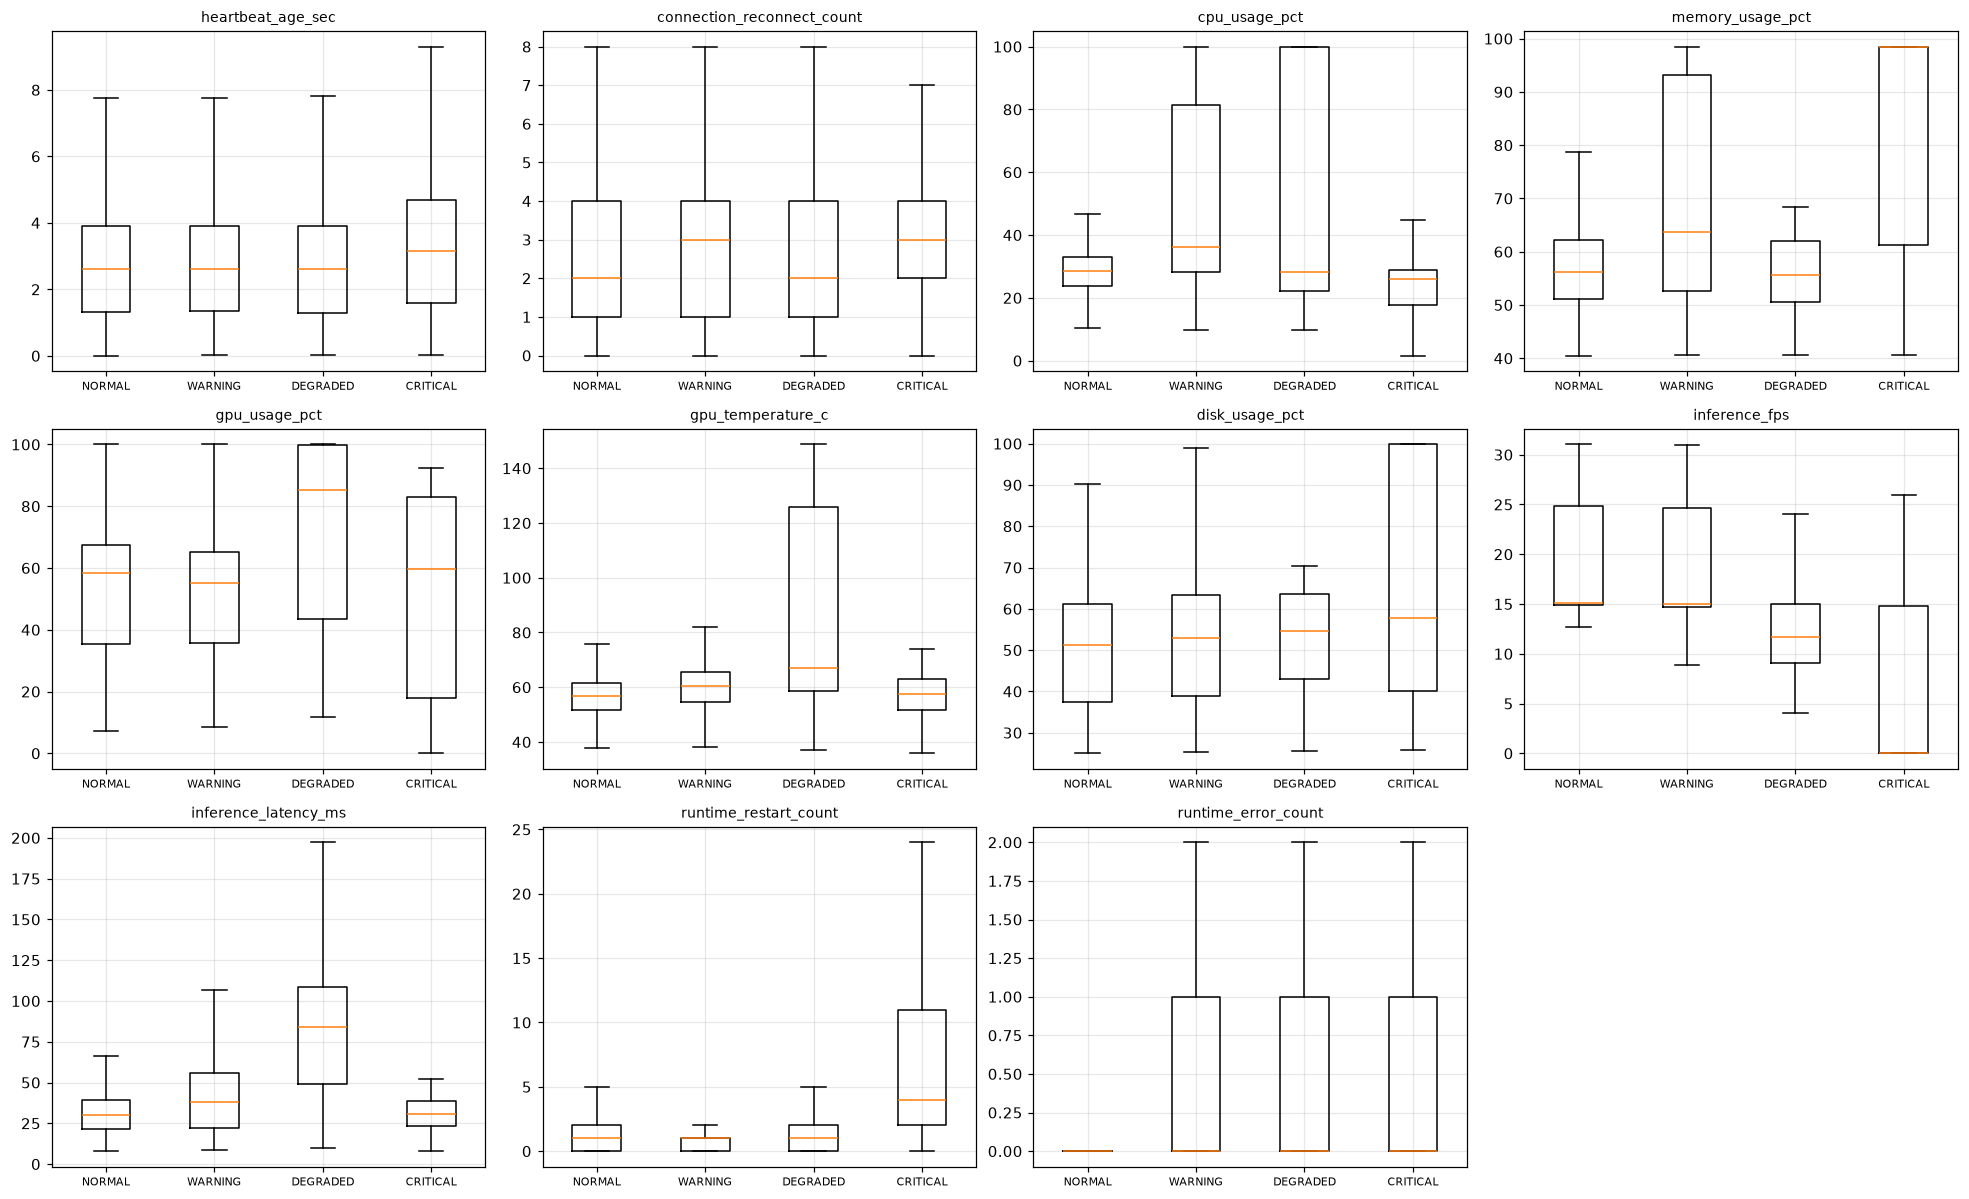

In [6]:
display(df[FEATURES].describe().T.round(2))
fig, axes = plt.subplots(3, 4, figsize=(18, 11)); axes = axes.ravel()
for ax, f in zip(axes, FEATURES):
    data = [df.loc[df.state == s, f].dropna().values for s in STATE_ORDER]
    ax.boxplot(data, showfliers=False); ax.set_xticks(range(1, 5), STATE_ORDER, fontsize=7); ax.set_title(f, fontsize=9)
axes[-1].axis("off"); plt.tight_layout(); plt.show()

### 4.4 Hành vi theo thời gian: một episode tiêu biểu mỗi kịch bản

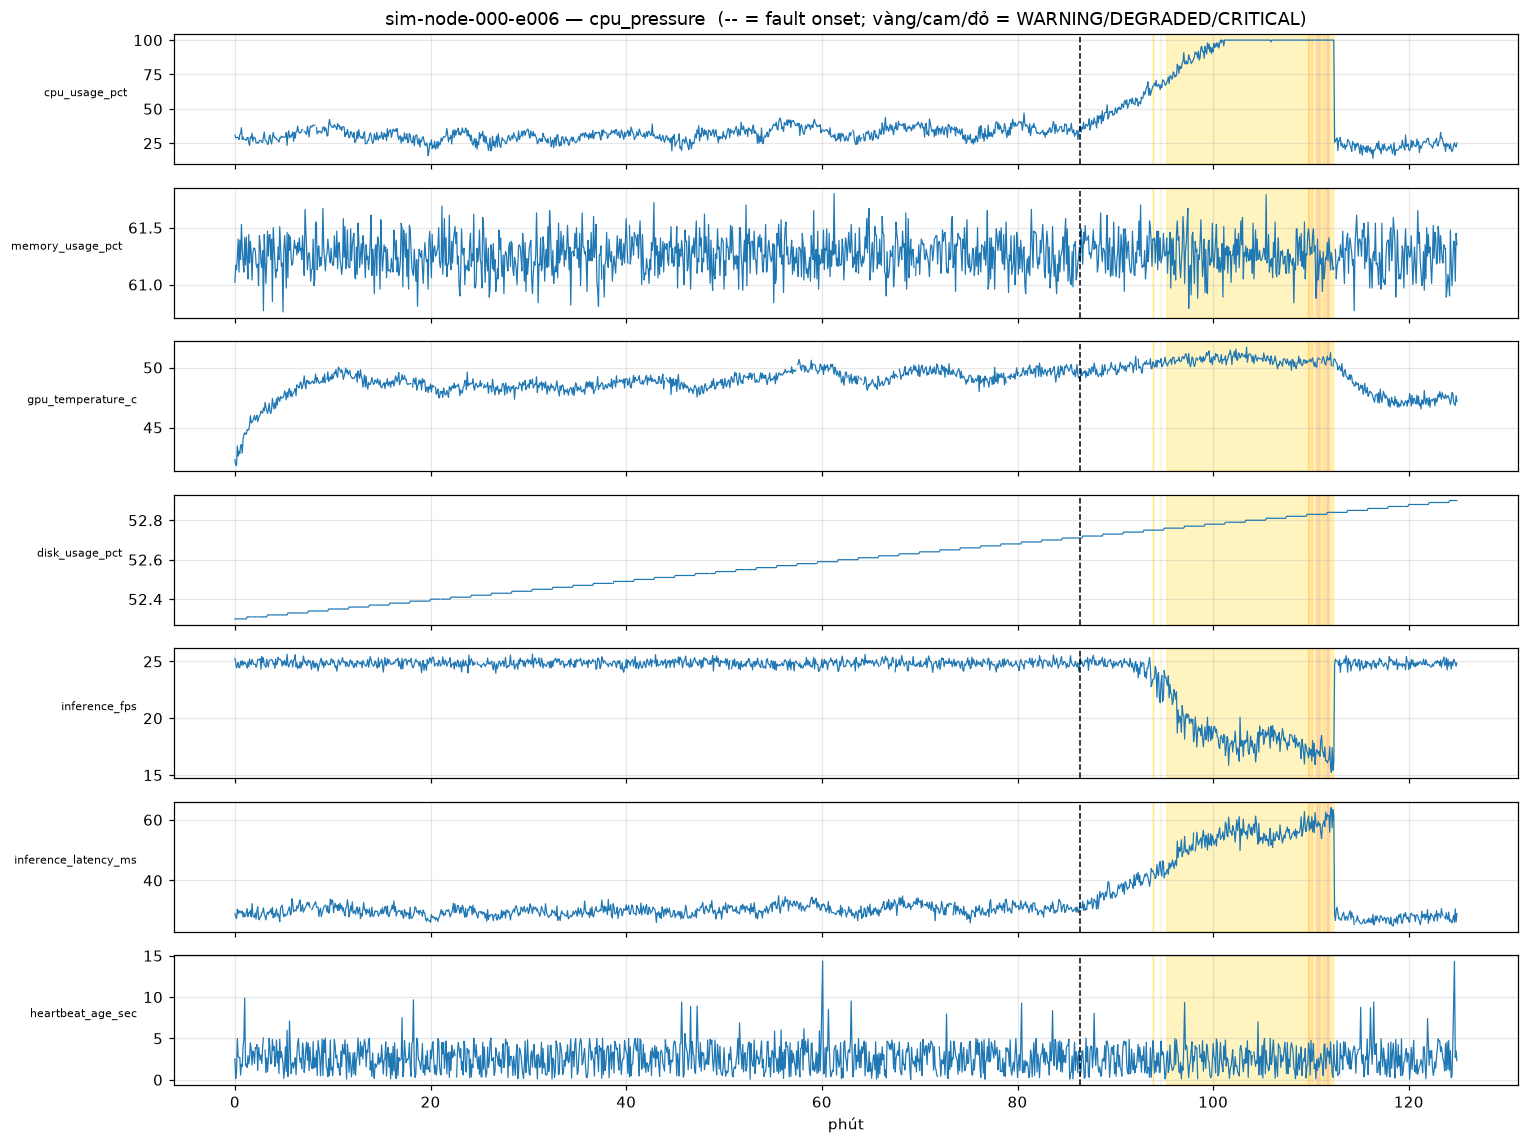

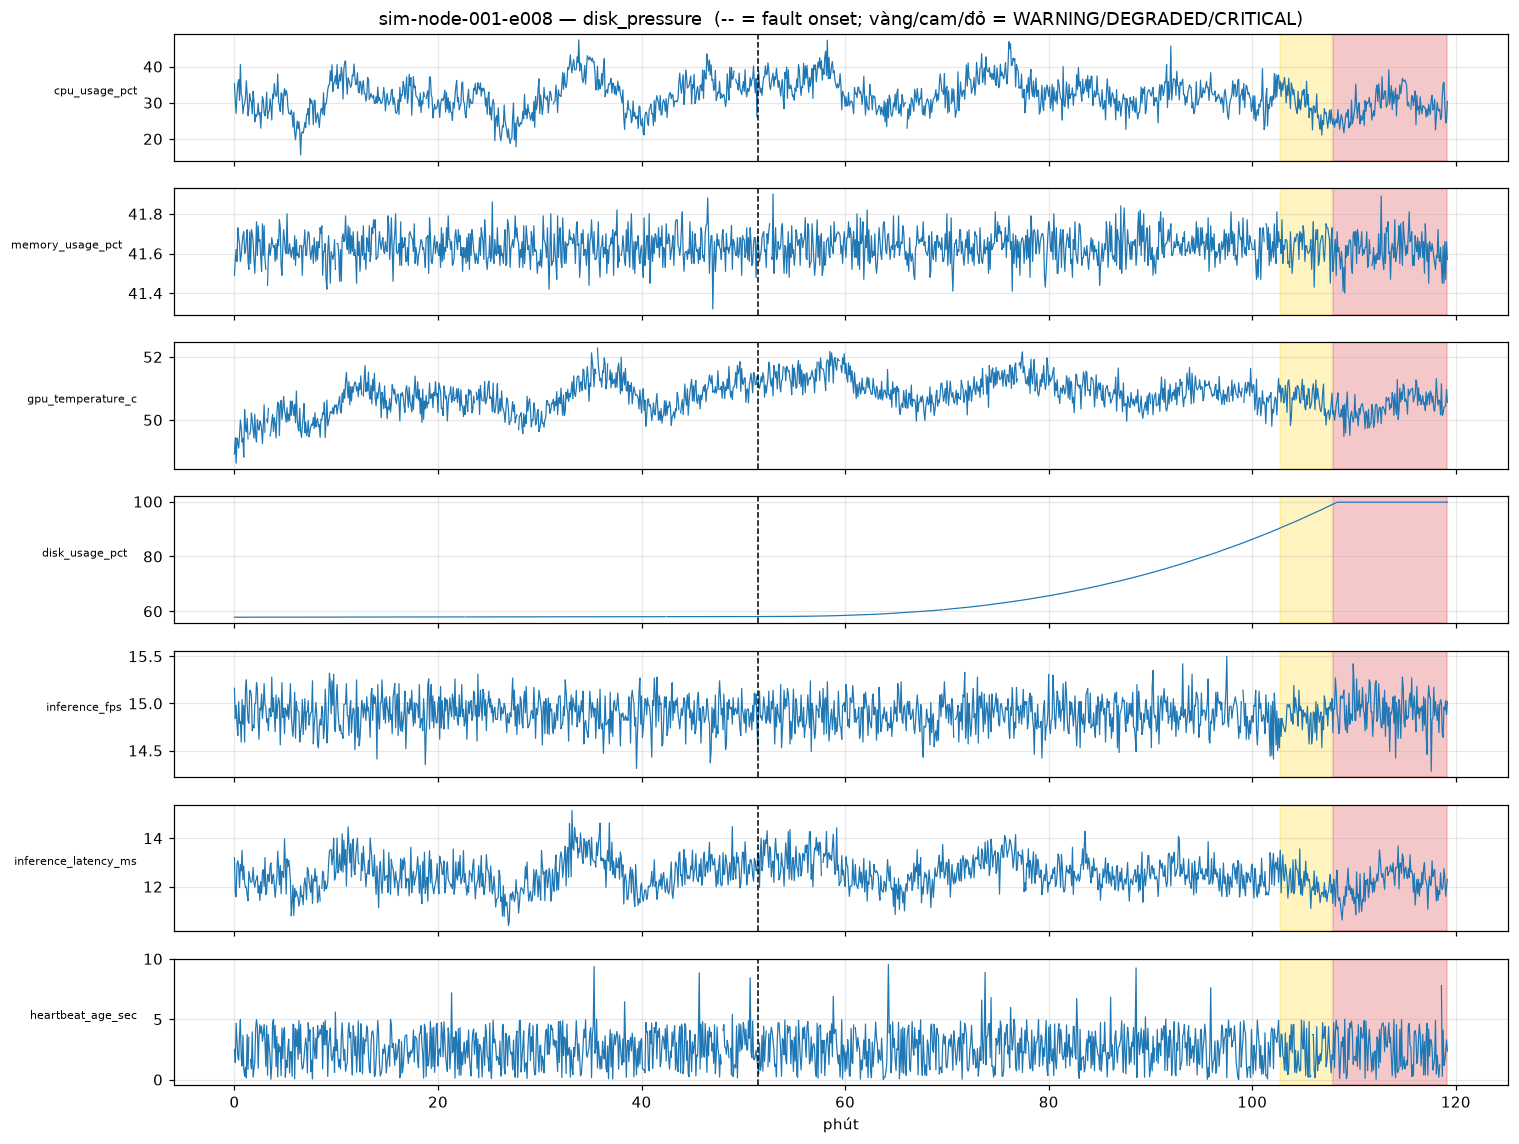

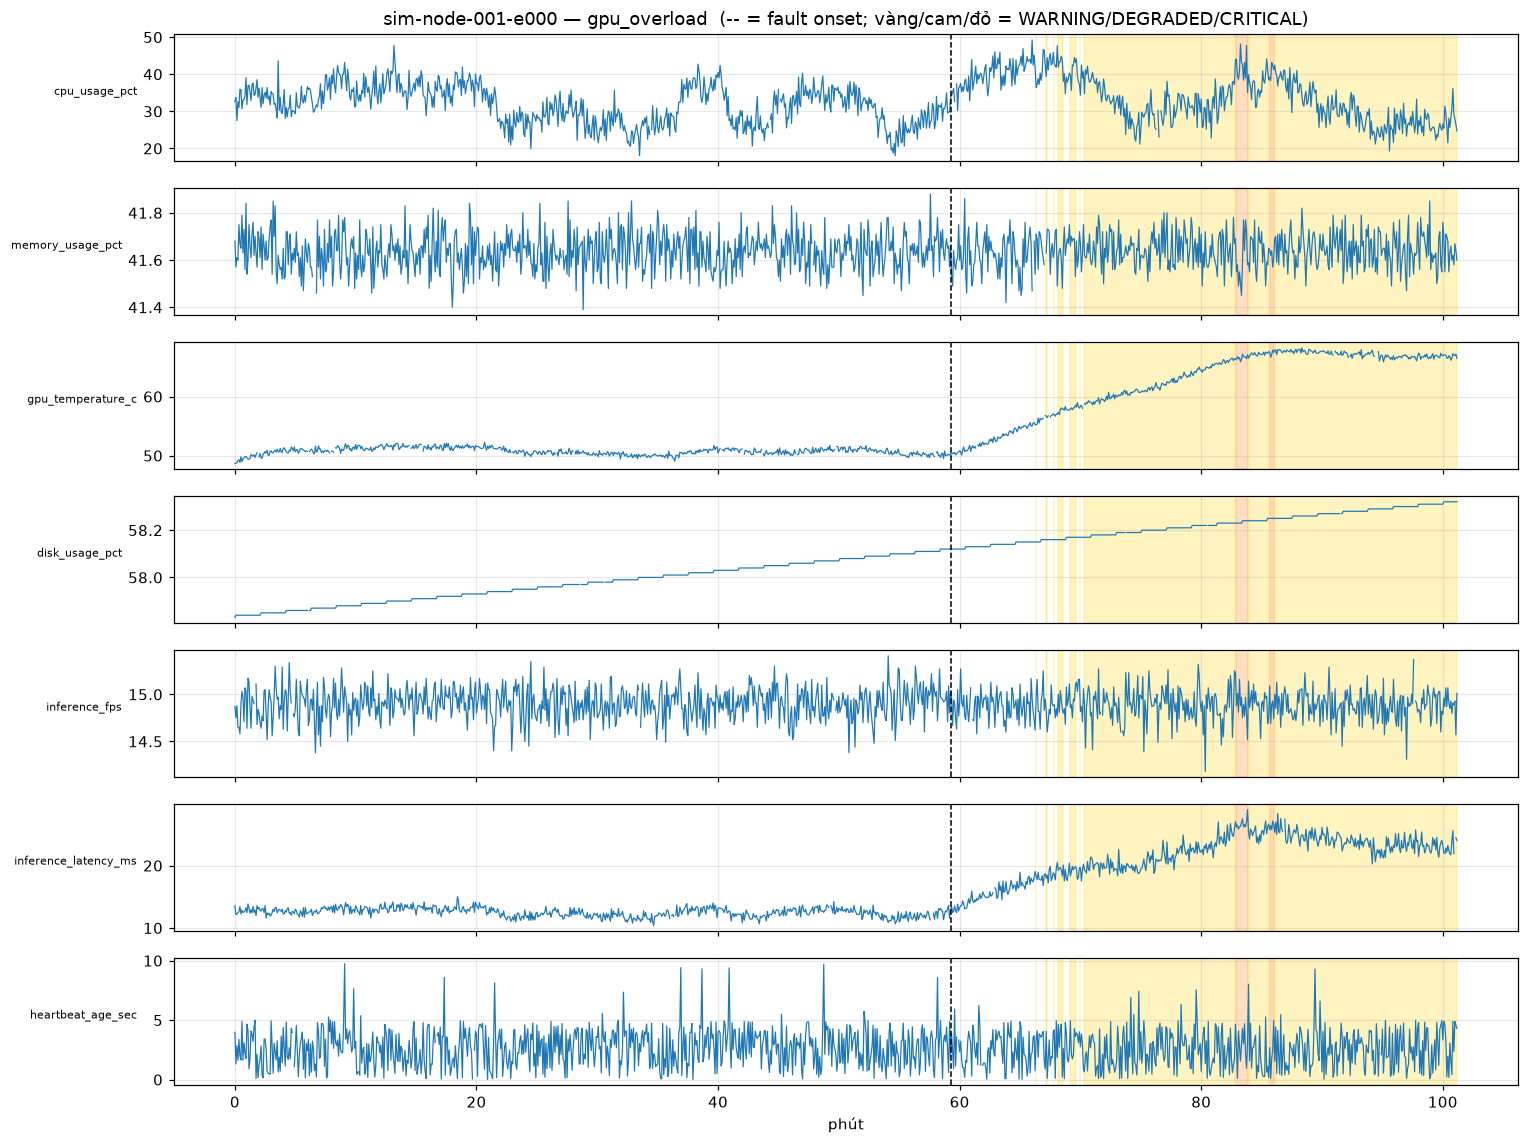

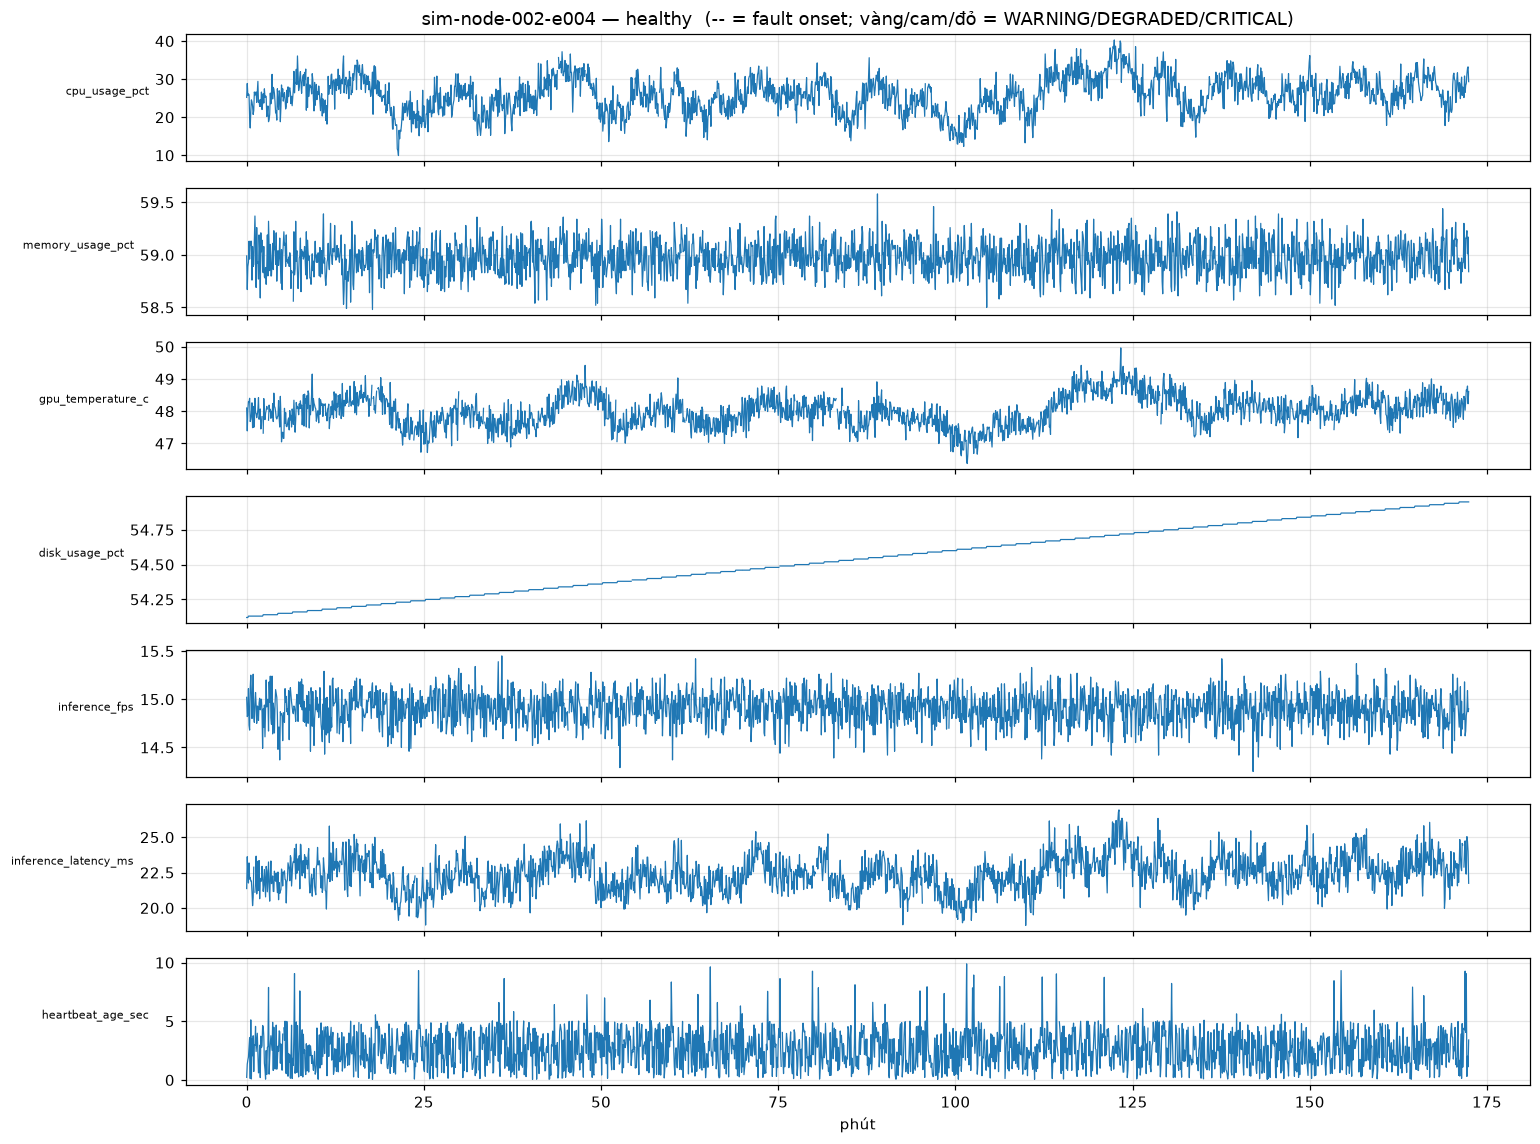

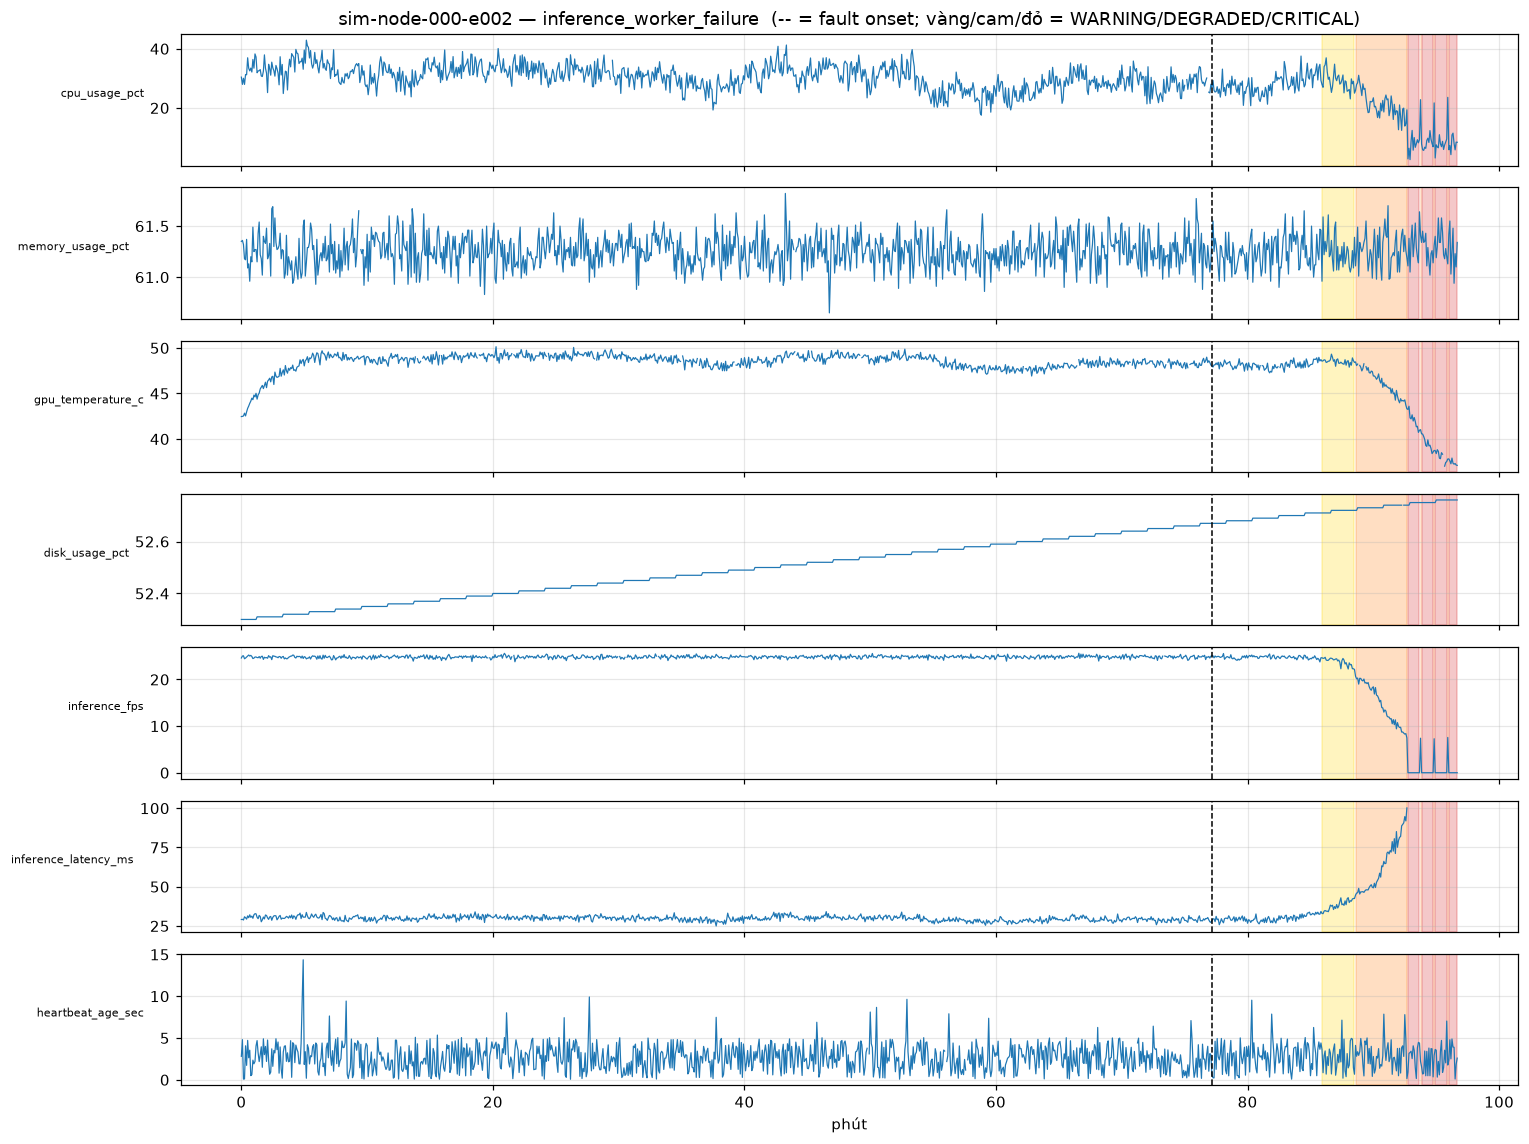

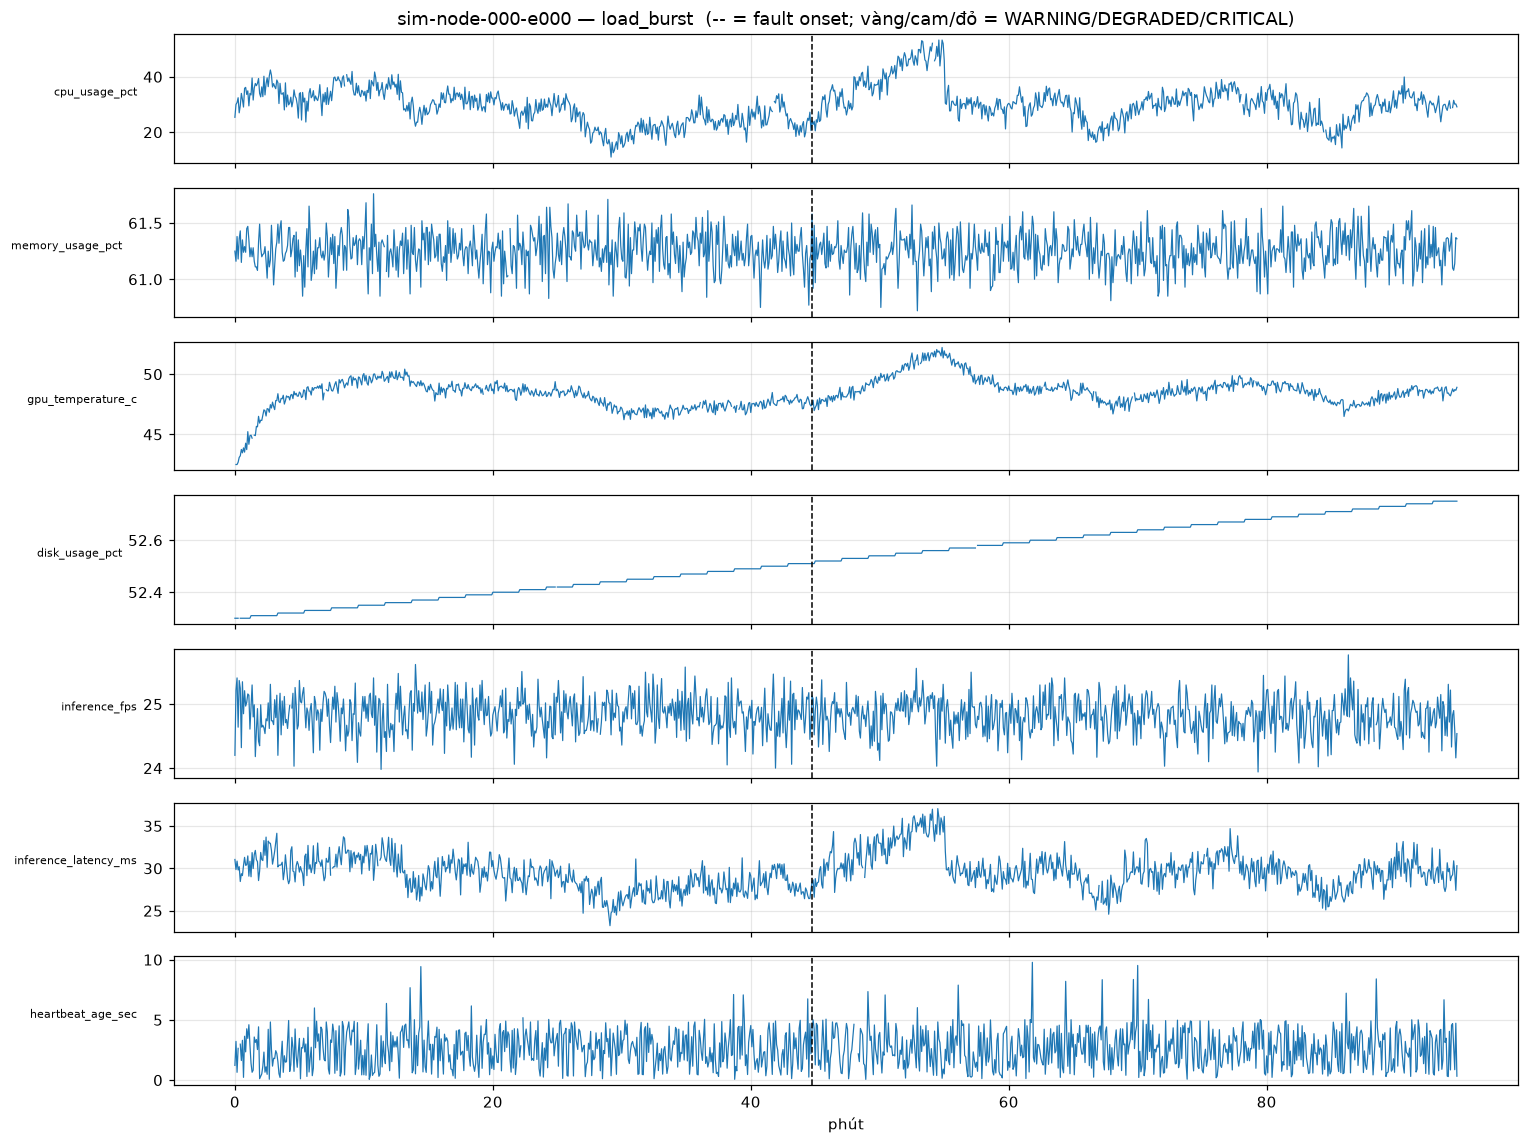

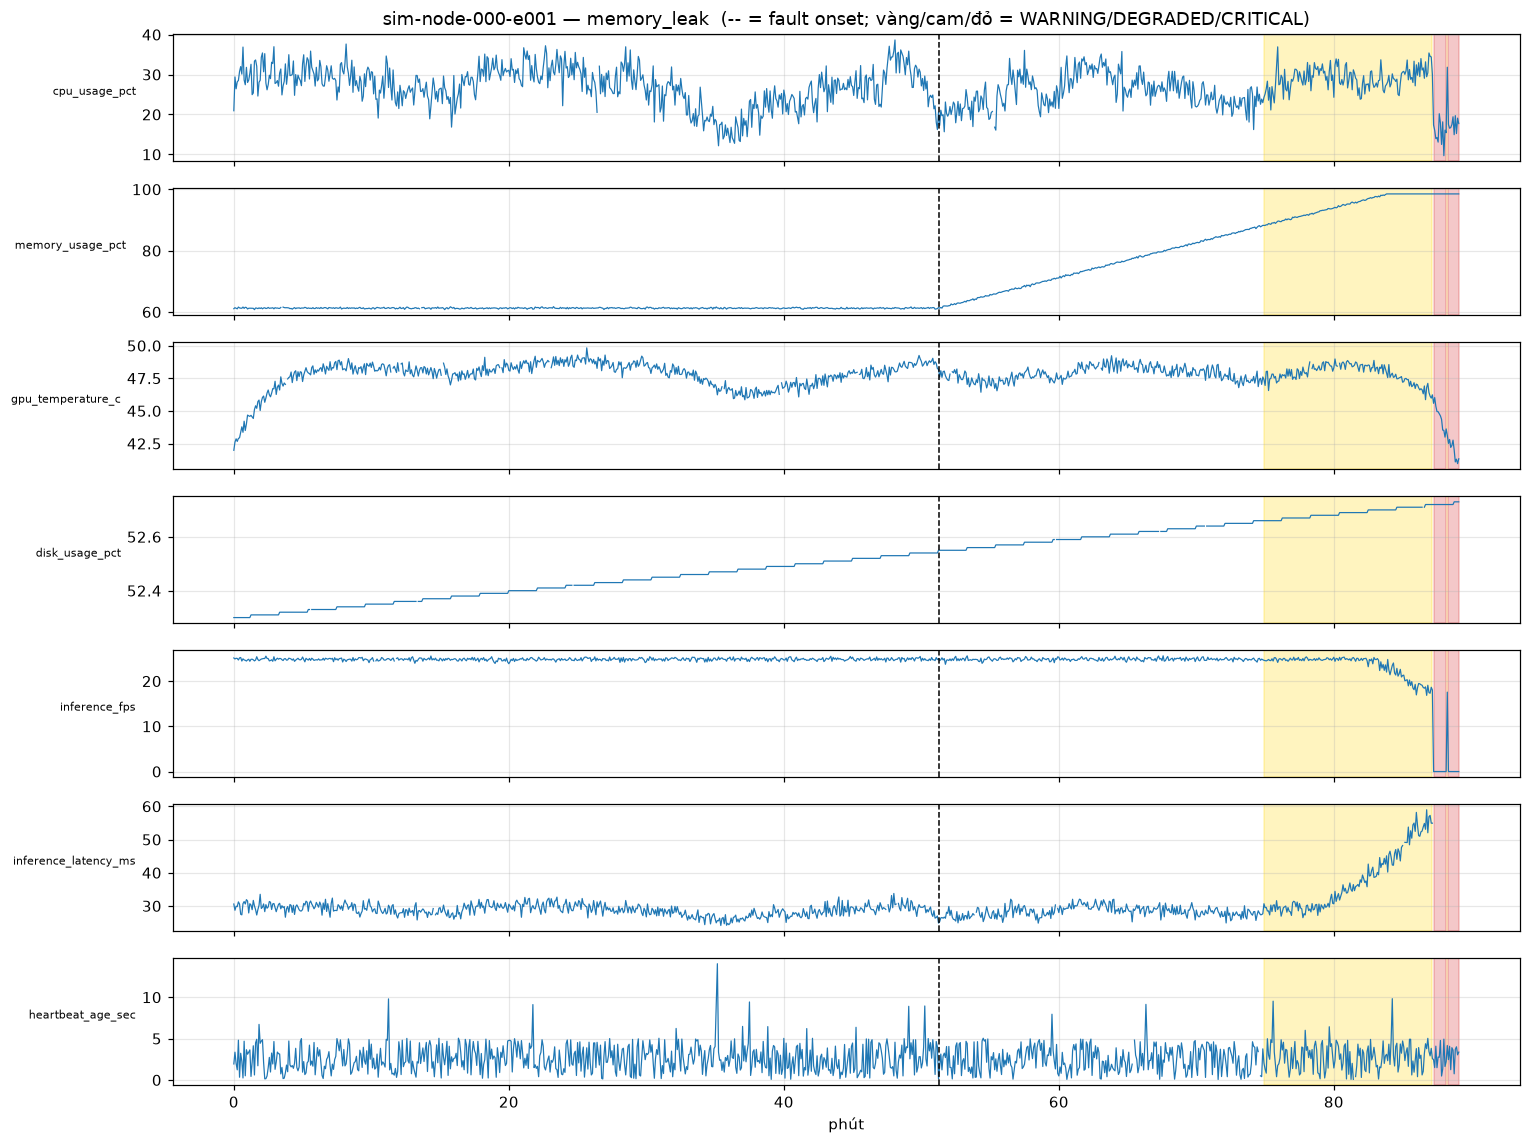

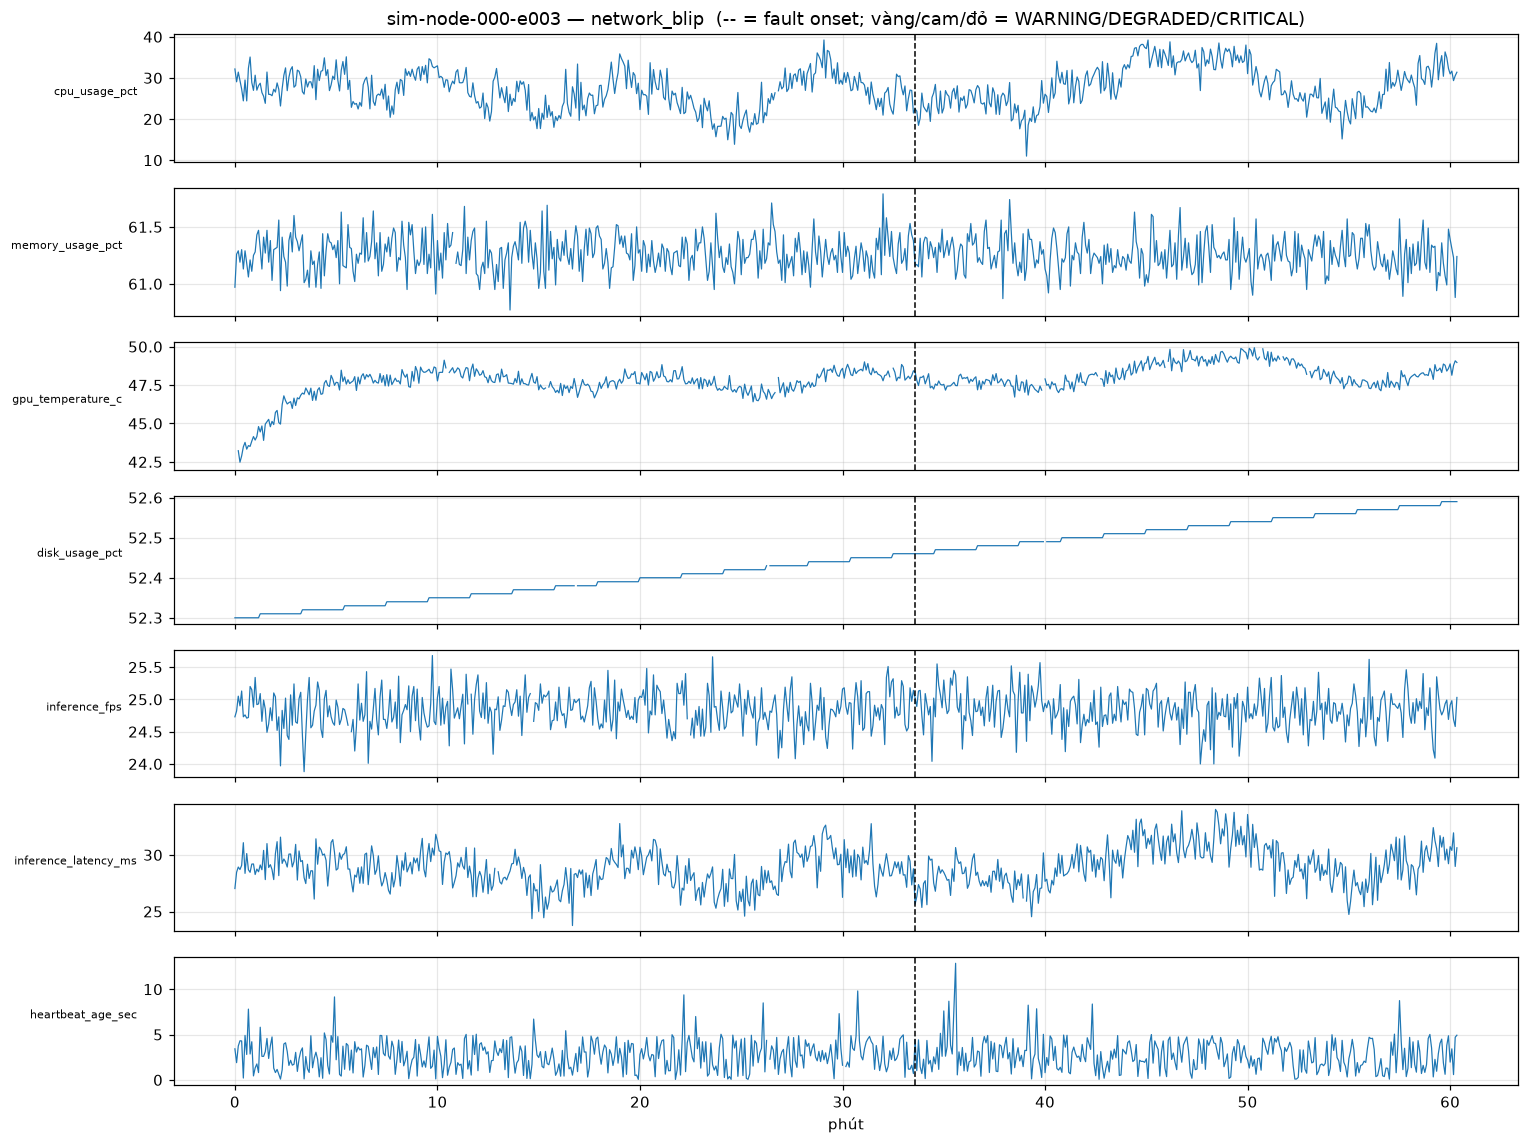

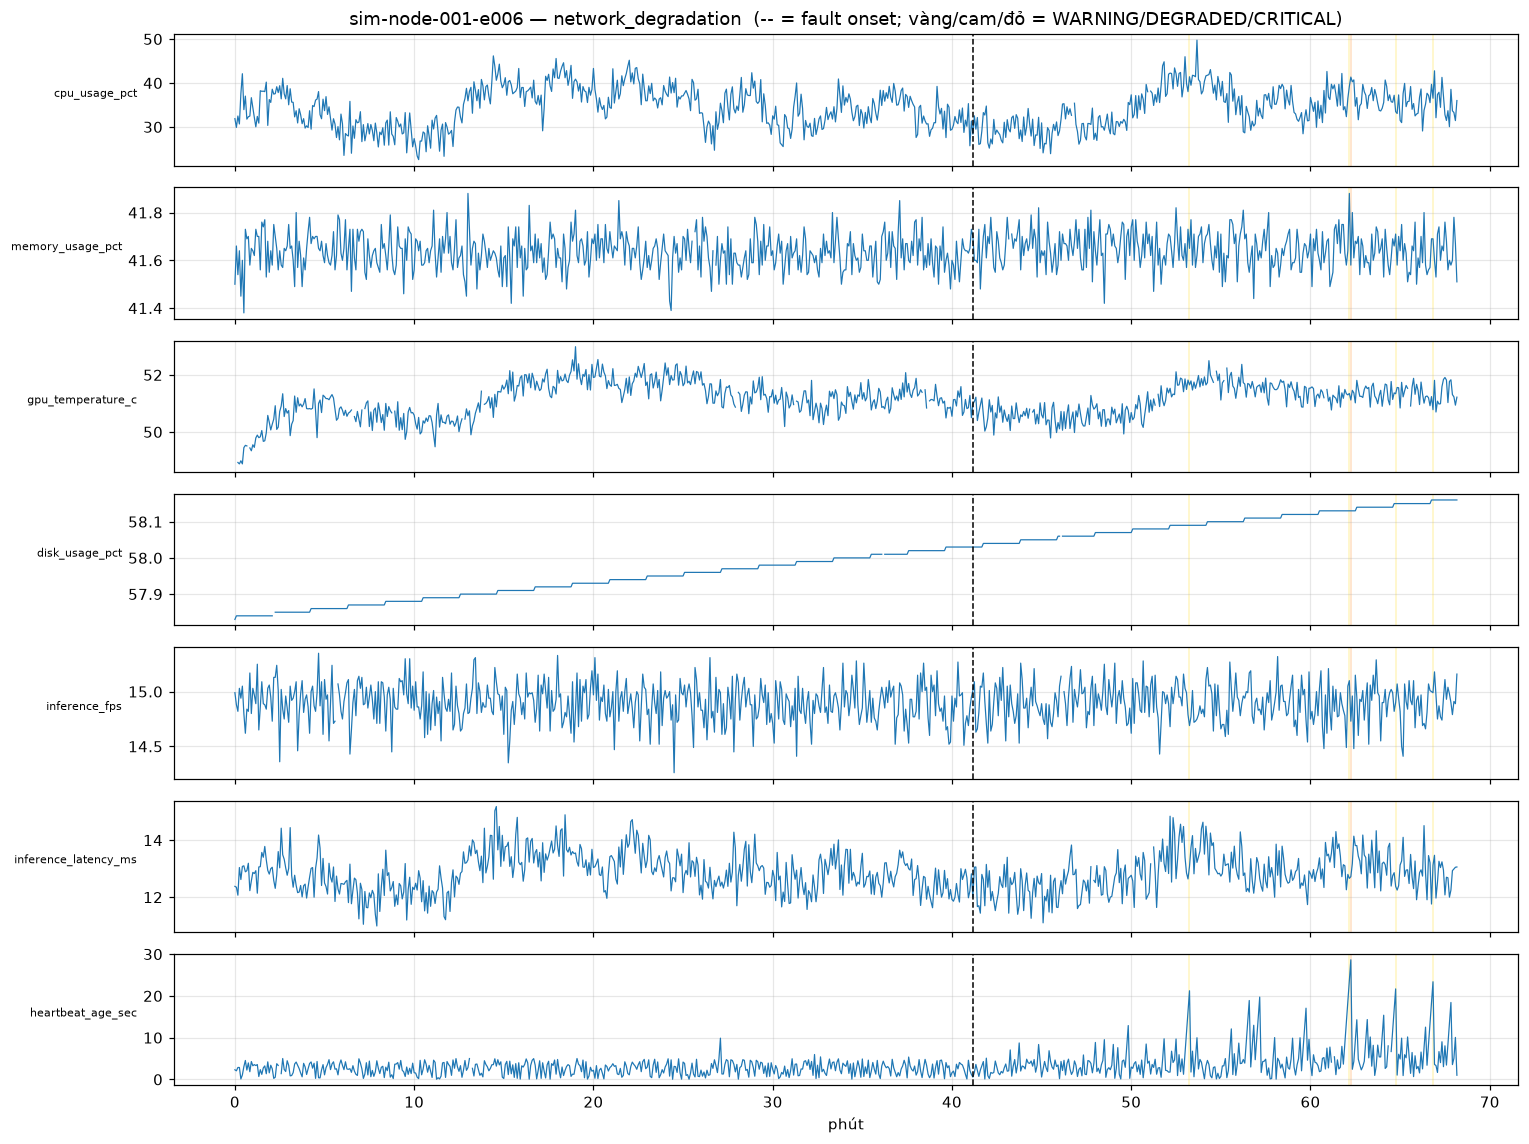

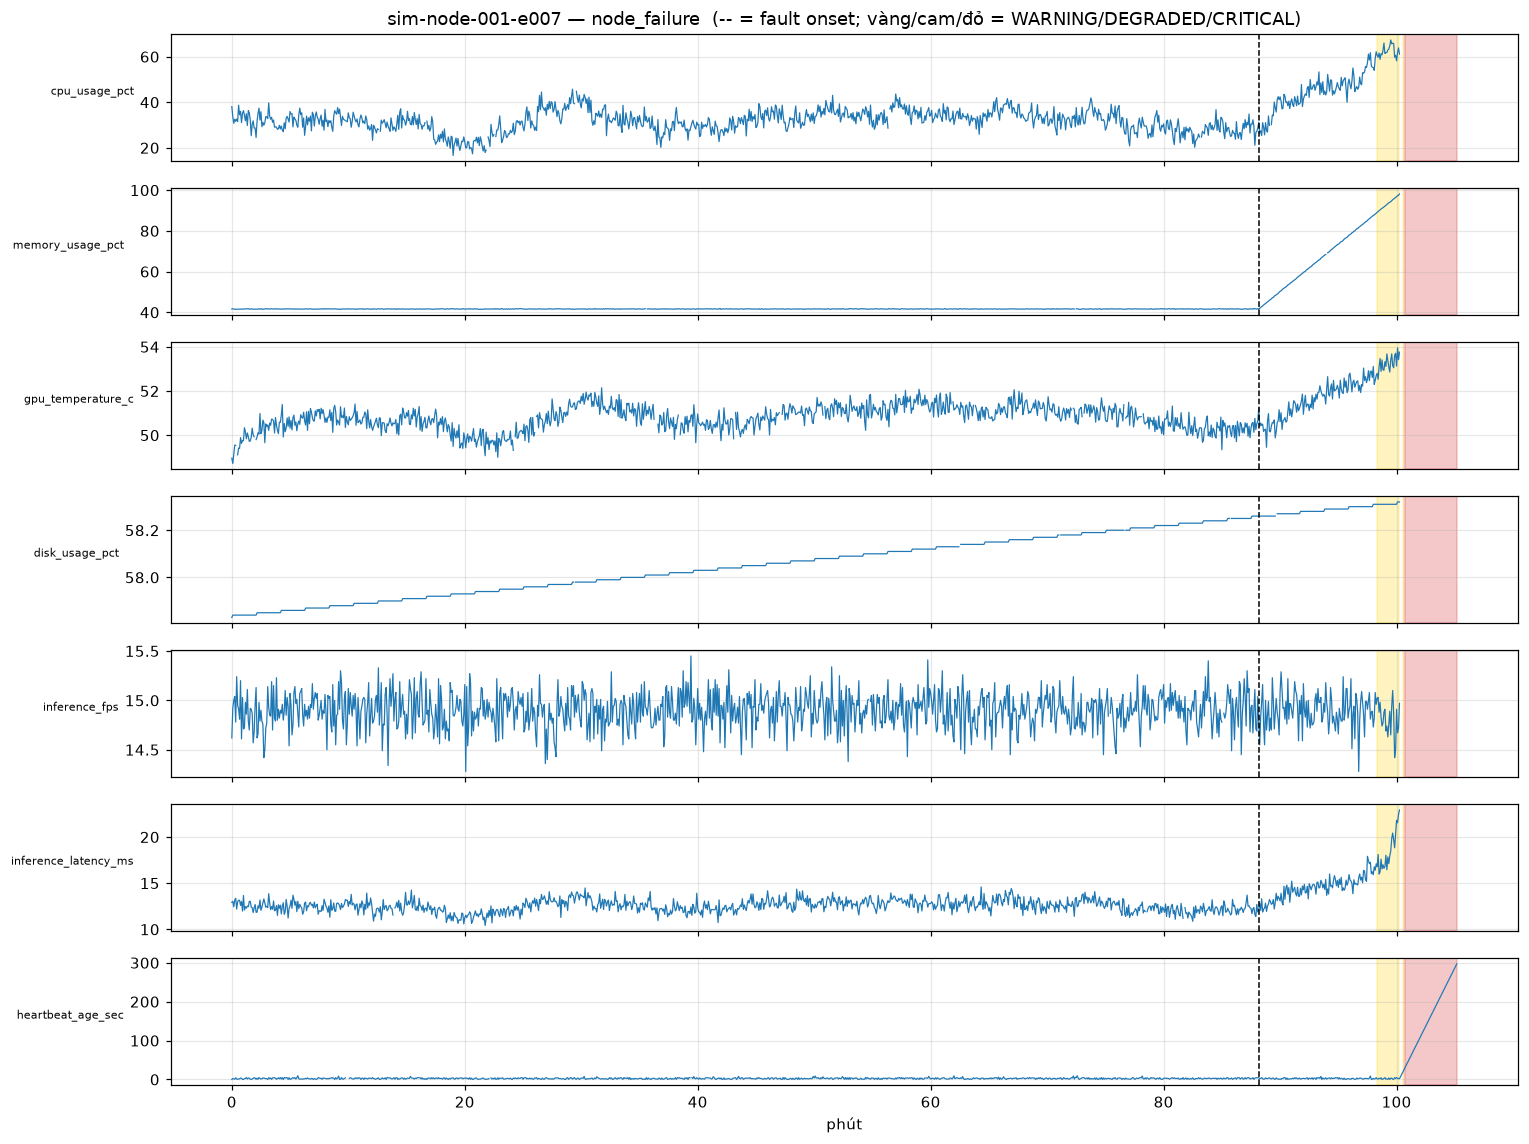

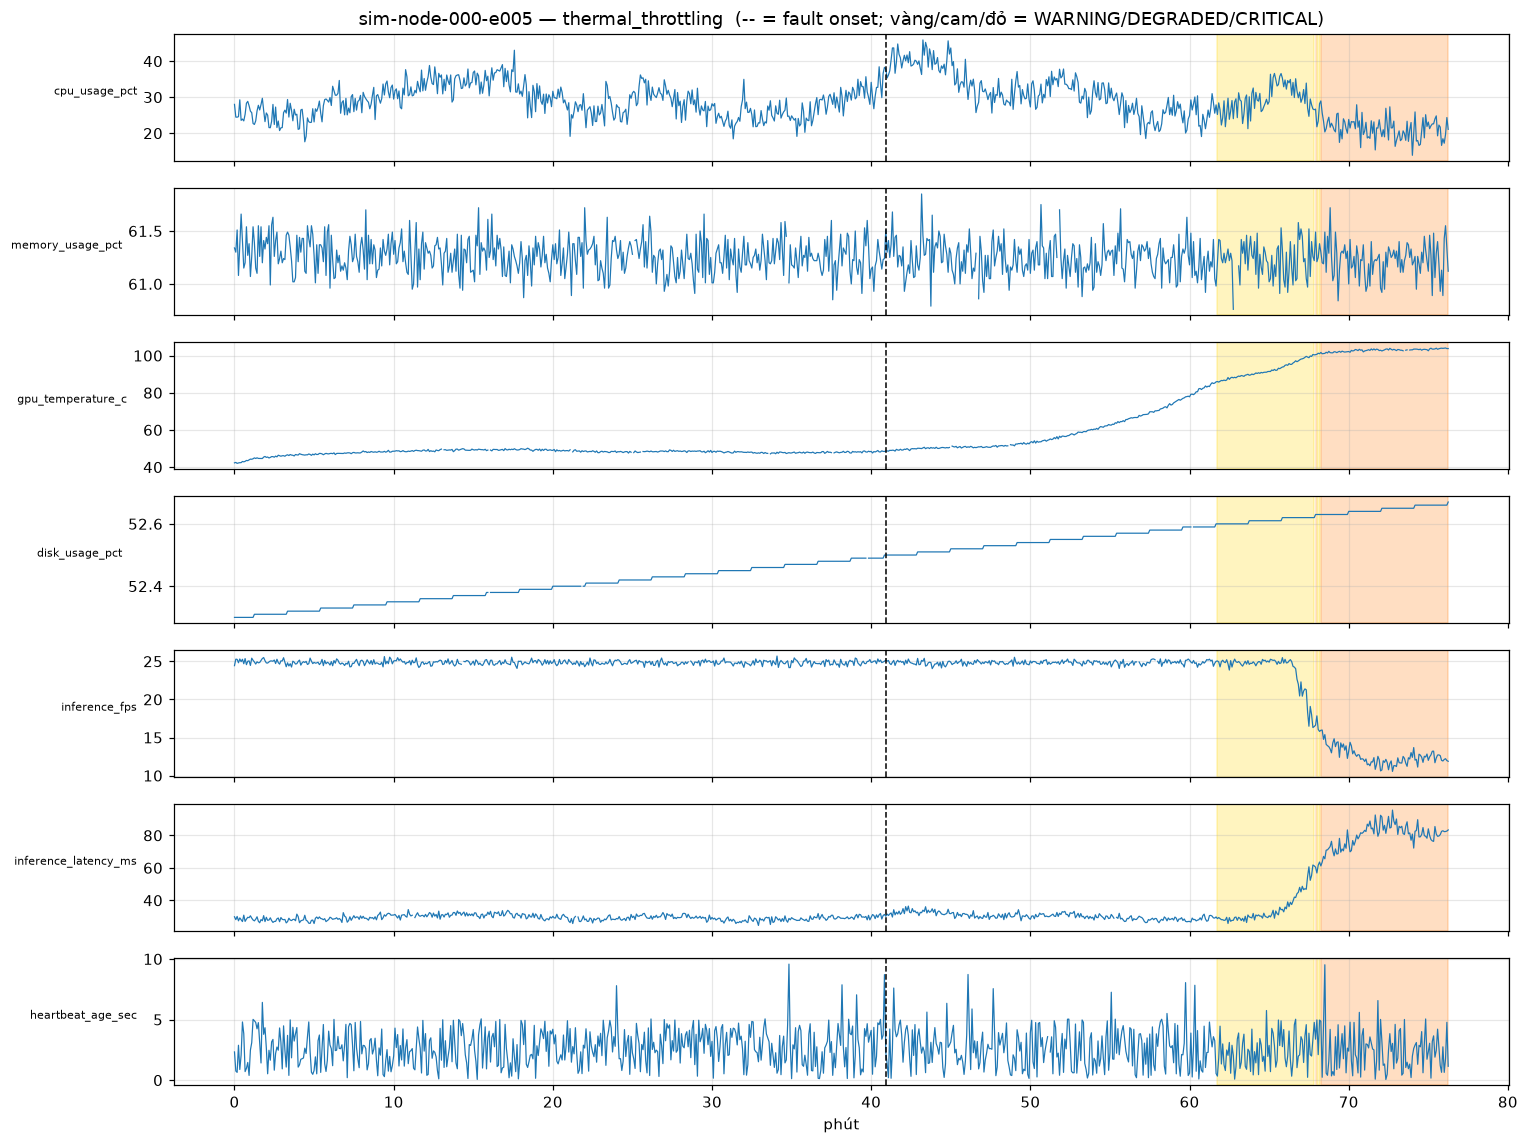

In [7]:
SHOW = ["cpu_usage_pct", "memory_usage_pct", "gpu_temperature_c", "disk_usage_pct",
        "inference_fps", "inference_latency_ms", "heartbeat_age_sec"]
COLORS = {"WARNING": "gold", "DEGRADED": "tab:orange", "CRITICAL": "tab:red"}

def plot_episode(ep_id):
    e = df[df.episode_id == ep_id].reset_index(drop=True)
    t = e.index * 5 / 60
    fig, axes = plt.subplots(len(SHOW), 1, figsize=(14, 1.5 * len(SHOW)), sharex=True)
    onset = e.index[e.phase == "ramp"]
    for ax, f in zip(axes, SHOW):
        ax.plot(t, e[f], lw=0.8); ax.set_ylabel(f, fontsize=7, rotation=0, ha="right")
        for s, c in COLORS.items():
            ax.fill_between(t, 0, 1, where=(e.state == s).values, color=c, alpha=0.25, transform=ax.get_xaxis_transform())
        if len(onset): ax.axvline(onset[0] * 5 / 60, color="k", ls="--", lw=1)
    axes[0].set_title(f"{ep_id} — {e.scenario[0]}  (-- = fault onset; vàng/cam/đỏ = WARNING/DEGRADED/CRITICAL)")
    axes[-1].set_xlabel("phút"); plt.tight_layout(); plt.show()

for sc in sorted(manifest.scenario.unique()):
    plot_episode(manifest[manifest.scenario == sc].episode_id.iloc[0])

**Quan sát.** Mỗi kịch bản có "chữ ký" riêng trước khi sập: memory tăng tuyến tính (leak), nhiệt tăng → FPS giảm
(thermal), latency tăng dần (worker/cpu/gpu), heartbeat chập chờn (network). Vì các tín hiệu này diễn ra theo
**xu hướng thời gian**, mô hình tuần tự có lợi thế so với nhìn một thời điểm.

### 4.5 Thời gian từ fault onset đến DEGRADED (giới hạn trên của lead time)

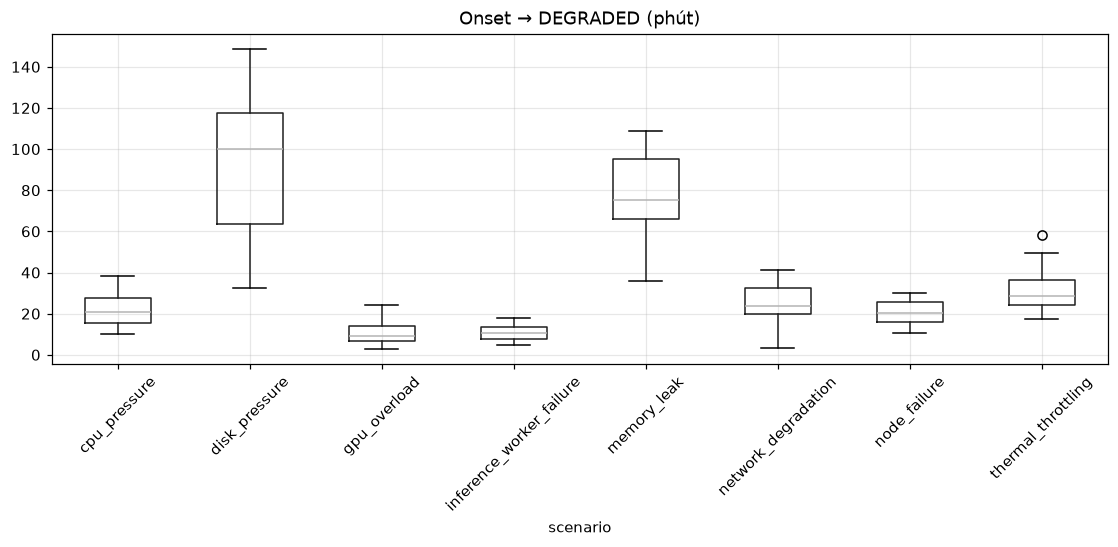

,count,50%,min,max
scenario,,,,
cpu_pressure,41.0,20.6,10.2,38.5
disk_pressure,25.0,99.9,32.2,148.8
gpu_overload,30.0,9.3,3.0,24.1
inference_worker_failure,31.0,10.5,4.8,17.8
memory_leak,28.0,75.2,36.0,108.8
network_degradation,29.0,23.5,3.2,41.1
node_failure,38.0,20.3,10.7,30.2
thermal_throttling,28.0,28.6,17.4,58.0


In [8]:
lt = manifest.dropna(subset=["lead_time_sec"]).assign(lead_min=lambda d: d.lead_time_sec / 60)
ax = lt.boxplot(column="lead_min", by="scenario", rot=45, figsize=(12, 4))
ax.set_title("Onset → DEGRADED (phút)"); plt.suptitle(""); plt.show()
display(lt.groupby("scenario").lead_min.describe()[["count", "50%", "min", "max"]].round(1))

### 4.6 Tương quan giữa các feature

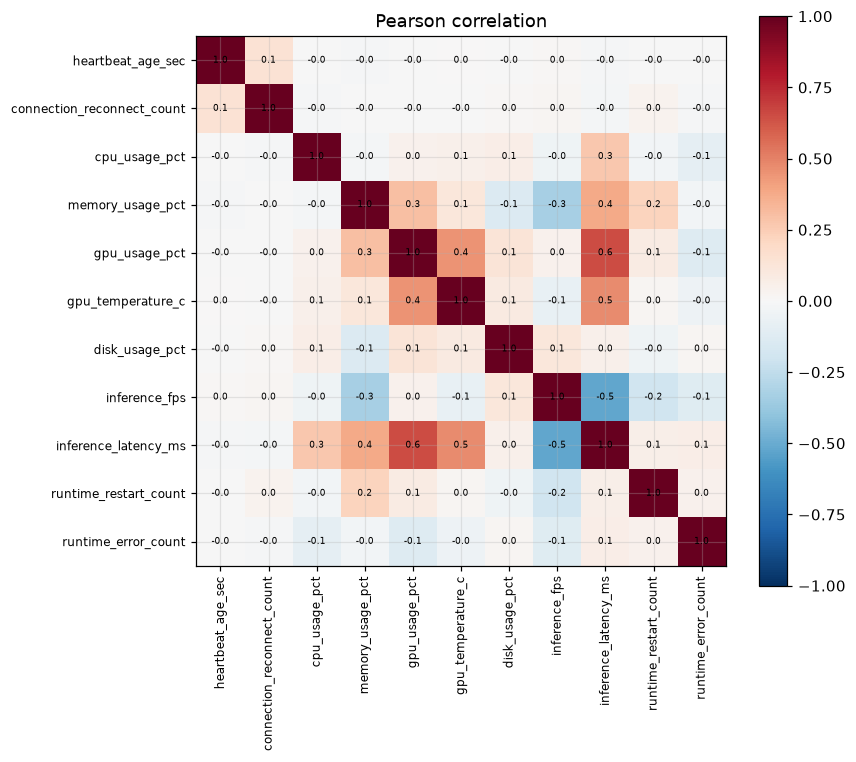

In [9]:
corr = df[FEATURES].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATURES)), FEATURES, rotation=90, fontsize=8); ax.set_yticks(range(len(FEATURES)), FEATURES, fontsize=8)
for i in range(len(FEATURES)):
    for j in range(len(FEATURES)):
        ax.text(j, i, f"{corr.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
plt.colorbar(im); plt.title("Pearson correlation"); plt.tight_layout(); plt.show()

## 5. Windowing

- Input: 60 bước (5 phút), stride 6 (30 s), tham số của `build`.
- Nhãn: `future_degradation` với horizon 120 bước (10 phút).
- Bỏ cửa sổ mà node **đã** DEGRADED/CRITICAL (lúc đó không còn là "dự đoán sớm") và cửa sổ bị kiểm duyệt ở cuối episode.
- Counter tích luỹ (`reconnect`, `restart`) → delta mỗi bước.
- **Chia theo node** (70/15/15) ⇒ val/test là node model chưa từng thấy; chuẩn hoá bằng mean/std của train.

In [10]:
if not NPZ.exists():
    print(build(DATA, NPZ))
d = np.load(NPZ, allow_pickle=False)
X = {p: d[f"X_{p}"] for p in ("train", "val", "test")}
Y = {p: d[f"y_{p}"].astype(np.float32) for p in X}
TTD = {p: d[f"ttd_{p}"] for p in X}
SC = {p: d[f"scenario_{p}"] for p in X}
SCEN = list(d["scenario_names"]); FEAT = list(d["feature_names"]); MEAN, STD = d["mean"], d["std"]
NODES = {p: list(d[f"nodes_{p}"]) for p in X}
for p in X:
    print(f"{p:5s} X={X[p].shape}  pos={Y[p].mean():.3f}  nodes={len(NODES[p])}")

train X=(54306, 60, 11)  pos=0.080  nodes=28
val   X=(11190, 60, 11)  pos=0.070  nodes=6
test  X=(12618, 60, 11)  pos=0.061  nodes=6


## 6. Baseline: Logistic Regression trên thống kê cửa sổ

Để biết LSTM có thực sự đáng giá, so sánh với baseline đơn giản dùng `last`, `mean`, `std`, `slope`
(các temporal feature của spec §15) trên từng feature.

In [11]:
def window_stats(x):
    t = np.arange(x.shape[1]) - (x.shape[1] - 1) / 2
    slope = (x * t[None, :, None]).sum(1) / (t ** 2).sum()
    return np.concatenate([x[:, -1], x.mean(1), x.std(1), slope], axis=1)

t0 = time.time()
logreg = LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5)
logreg.fit(window_stats(X["train"]), Y["train"])
p_lr = {p: logreg.predict_proba(window_stats(X[p]))[:, 1] for p in ("val", "test")}
print(f"LogReg ({time.time() - t0:.1f}s)  val PR-AUC={average_precision_score(Y['val'], p_lr['val']):.3f}  "
      f"test PR-AUC={average_precision_score(Y['test'], p_lr['test']):.3f}  test ROC-AUC={roc_auc_score(Y['test'], p_lr['test']):.3f}")

LogReg (1.4s)  val PR-AUC=0.667  test PR-AUC=0.709  test ROC-AUC=0.926


## 7. LSTM

Kiến trúc: `LSTM(2 lớp, hidden 64, dropout 0.2)` → hidden state cuối → `MLP` → logit.
- Loss: `BCEWithLogits` với `pos_weight = #neg/#pos` để bù mất cân bằng.
- Chọn checkpoint theo **val PR-AUC** (thước đo phù hợp khi mẫu dương hiếm), early stopping patience 5.

In [12]:
class NodeHealthLSTM(nn.Module):
    def __init__(self, n_features, hidden=64, layers=2, dropout=0.2):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden, layers, batch_first=True, dropout=dropout)
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Dropout(dropout), nn.Linear(32, 1))

    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return self.head(h[-1]).squeeze(-1)

CFG = dict(hidden=64, layers=2, dropout=0.2, lr=1e-3, batch=256, epochs=30, patience=5)
model = NodeHealthLSTM(len(FEAT), CFG["hidden"], CFG["layers"], CFG["dropout"]).to(DEVICE)
print(model, "\nparams:", sum(p.numel() for p in model.parameters()))

NodeHealthLSTM(
  (lstm): LSTM(11, 64, num_layers=2, batch_first=True, dropout=0.2)
  (head): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
) 
params: 55105


In [13]:
def loader(p, shuffle):
    ds = torch.utils.data.TensorDataset(torch.from_numpy(X[p]), torch.from_numpy(Y[p]))
    return torch.utils.data.DataLoader(ds, batch_size=CFG["batch"], shuffle=shuffle)

@torch.no_grad()
def predict(m, x, bs=2048):
    m.eval()
    return np.concatenate([torch.sigmoid(m(torch.from_numpy(x[i:i + bs]).to(DEVICE))).cpu().numpy()
                           for i in range(0, len(x), bs)])

pos_weight = torch.tensor((1 - Y["train"].mean()) / Y["train"].mean(), device=DEVICE)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=1e-4)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)

hist, best, bad = [], -1, 0
for ep in range(1, CFG["epochs"] + 1):
    model.train(); t0 = time.time(); tot = 0
    for xb, yb in loader("train", True):
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        opt.zero_grad(); loss = loss_fn(model(xb), yb); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tot += loss.item() * len(xb)
    pv = predict(model, X["val"])
    vloss = loss_fn(torch.logit(torch.from_numpy(pv).clamp(1e-6, 1 - 1e-6)).to(DEVICE),
                    torch.from_numpy(Y["val"]).to(DEVICE)).item()
    ap = average_precision_score(Y["val"], pv); sched.step(ap)
    hist.append(dict(epoch=ep, train_loss=tot / len(Y["train"]), val_loss=vloss, val_pr_auc=ap,
                     val_roc_auc=roc_auc_score(Y["val"], pv), lr=opt.param_groups[0]["lr"]))
    print(f"ep {ep:2d}  loss {hist[-1]['train_loss']:.4f}  val_loss {vloss:.4f}  val PR-AUC {ap:.4f}  "
          f"ROC-AUC {hist[-1]['val_roc_auc']:.4f}  ({time.time() - t0:.0f}s)")
    if ap > best:
        best, bad = ap, 0; torch.save(model.state_dict(), OUT / "lstm_best.pt")
    else:
        bad += 1
        if bad >= CFG["patience"]: print("early stop"); break
model.load_state_dict(torch.load(OUT / "lstm_best.pt")); hist = pd.DataFrame(hist)

ep  1  loss 0.7583  val_loss 0.6183  val PR-AUC 0.6895  ROC-AUC 0.9061  (19s)


ep  2  loss 0.5686  val_loss 0.6162  val PR-AUC 0.7146  ROC-AUC 0.8953  (24s)


ep  3  loss 0.5116  val_loss 0.6601  val PR-AUC 0.7327  ROC-AUC 0.8941  (25s)


ep  4  loss 0.4911  val_loss 0.6313  val PR-AUC 0.7264  ROC-AUC 0.9194  (27s)


ep  5  loss 0.4586  val_loss 0.6696  val PR-AUC 0.7614  ROC-AUC 0.9008  (21s)


ep  6  loss 0.4579  val_loss 0.5648  val PR-AUC 0.7777  ROC-AUC 0.9210  (22s)


ep  7  loss 0.4407  val_loss 0.6196  val PR-AUC 0.7570  ROC-AUC 0.9183  (29s)


ep  8  loss 0.4321  val_loss 0.5956  val PR-AUC 0.7765  ROC-AUC 0.9229  (28s)


ep  9  loss 0.4126  val_loss 0.6353  val PR-AUC 0.7538  ROC-AUC 0.9205  (26s)


ep 10  loss 0.3871  val_loss 0.6314  val PR-AUC 0.7709  ROC-AUC 0.9169  (36s)


ep 11  loss 0.3704  val_loss 0.6781  val PR-AUC 0.7431  ROC-AUC 0.9153  (45s)
early stop


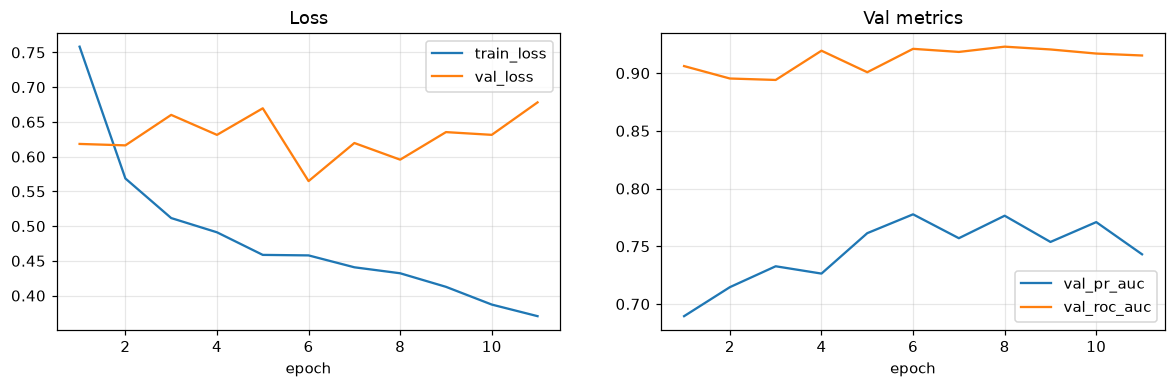

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
hist.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="Loss")
hist.plot(x="epoch", y=["val_pr_auc", "val_roc_auc"], ax=ax[1], title="Val metrics"); plt.show()

## 8. Đánh giá trên test (node chưa từng thấy)

Ngưỡng quyết định chọn trên **val** (tối đa F1) rồi áp nguyên cho test, không nhìn test khi chọn.

In [15]:
p_val, p_test = predict(model, X["val"]), predict(model, X["test"])
pr, rc, th = precision_recall_curve(Y["val"], p_val)
f1 = 2 * pr * rc / (pr + rc + 1e-9); THR = float(th[np.argmax(f1[:-1])])
print(f"Ngưỡng (val, max F1) = {THR:.3f}")

summary = pd.DataFrame({
    "LogReg": [average_precision_score(Y["test"], p_lr["test"]), roc_auc_score(Y["test"], p_lr["test"])],
    "LSTM": [average_precision_score(Y["test"], p_test), roc_auc_score(Y["test"], p_test)],
}, index=["PR-AUC", "ROC-AUC"]).round(4)
display(summary)
yhat = (p_test >= THR).astype(int)
print(classification_report(Y["test"], yhat, target_names=["ổn định", "sắp suy giảm"], digits=3))
print("Confusion matrix:\n", confusion_matrix(Y["test"], yhat))

Ngưỡng (val, max F1) = 0.821


,LogReg,LSTM
PR-AUC,0.7092,0.6982
ROC-AUC,0.9262,0.8702


              precision    recall  f1-score   support

     ổn định      0.980     0.975     0.978     11854
sắp suy giảm      0.643     0.686     0.664       764

    accuracy                          0.958     12618
   macro avg      0.811     0.831     0.821     12618
weighted avg      0.959     0.958     0.959     12618

Confusion matrix:
 [[11563   291]
 [  240   524]]


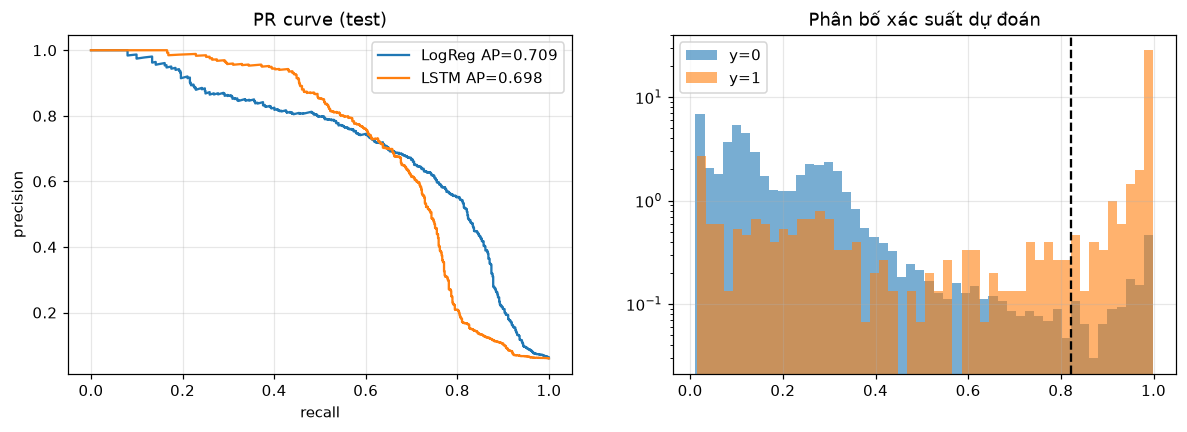

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, p in [("LogReg", p_lr["test"]), ("LSTM", p_test)]:
    pr_, rc_, _ = precision_recall_curve(Y["test"], p)
    ax[0].plot(rc_, pr_, label=f"{name} AP={average_precision_score(Y['test'], p):.3f}")
ax[0].set(xlabel="recall", ylabel="precision", title="PR curve (test)"); ax[0].legend()
ax[1].hist(p_test[Y["test"] == 0], bins=50, alpha=0.6, label="y=0", density=True)
ax[1].hist(p_test[Y["test"] == 1], bins=50, alpha=0.6, label="y=1", density=True)
ax[1].axvline(THR, color="k", ls="--"); ax[1].set(title="Phân bố xác suất dự đoán", yscale="log"); ax[1].legend(); plt.show()

## 9. Phân tích kết quả
### 9.1 Theo kịch bản

In [17]:
rows = []
for i, sc in enumerate(SCEN):
    m = SC["test"] == i
    if not m.any(): continue
    y, yh = Y["test"][m], yhat[m]
    rows.append(dict(scenario=sc, windows=int(m.sum()), positives=int(y.sum()),
                     recall=yh[y == 1].mean() if y.sum() else np.nan,
                     false_alarm_rate=yh[y == 0].mean(),
                     pr_auc=average_precision_score(y, p_test[m]) if 0 < y.sum() < len(y) else np.nan))
per_sc = pd.DataFrame(rows).set_index("scenario").round(3)
display(per_sc)

,windows,positives,recall,false_alarm_rate,pr_auc
scenario,,,,,
load_burst,976,0,NaN,0.002,NaN
memory_leak,1339,84,0.917,0.072,0.902
inference_worker_failure,471,60,0.133,0.007,0.291
network_blip,423,0,NaN,0.054,NaN
thermal_throttling,805,100,0.730,0.001,0.853
cpu_pressure,787,127,1.000,0.141,0.958
gpu_overload,1018,132,0.606,0.032,0.724
network_degradation,471,59,0.339,0.015,0.640
node_failure,1050,122,0.811,0.026,0.866


`false_alarm_rate` trên `healthy`/`load_burst`/`network_blip` là thước đo quan trọng nhất cho vận hành:
một model báo động giả nhiều sẽ bị operator bỏ qua.

### 9.2 Recall theo thời gian còn lại trước khi suy giảm

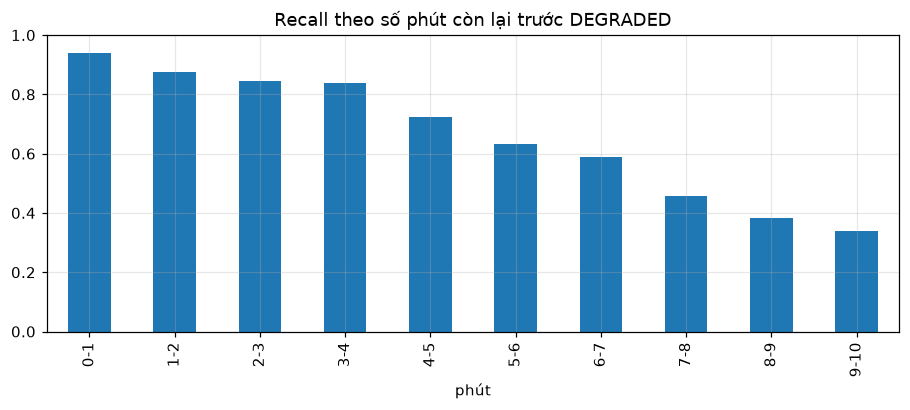

In [18]:
pos = Y["test"] == 1
bins = np.arange(0, 601, 60)
hit = yhat[pos]; idx = np.digitize(TTD["test"][pos], bins) - 1
rec = pd.Series([hit[idx == k].mean() for k in range(len(bins) - 1)],
                index=[f"{b // 60}-{b // 60 + 1}" for b in bins[:-1]])
rec.plot.bar(figsize=(10, 3.5), title="Recall theo số phút còn lại trước DEGRADED", ylim=(0, 1)); plt.xlabel("phút"); plt.show()

Kỳ vọng: recall cao khi sự cố sắp tới (0–2 phút), giảm dần khi còn xa, vì càng xa tín hiệu càng yếu.

### 9.3 Mô phỏng vận hành: chạy model liên tục trên từng episode của node test

Trượt cửa sổ từng bước (5 s) như khi triển khai thật; báo động khi xác suất ≥ ngưỡng trong **3 mẫu liên tiếp**.
- **Lead time** = thời điểm DEGRADED đầu tiên − thời điểm báo động đầu tiên (chỉ tính báo động sau fault onset).
- **False alarms / giờ** trên các episode benign.

In [19]:
def stream_probs(x, window=60):
    z = np.nan_to_num((x - MEAN) / STD, nan=0.0).astype(np.float32)
    wins = np.lib.stride_tricks.sliding_window_view(z, window, axis=0).transpose(0, 2, 1)
    p = np.full(len(z), np.nan); p[window - 1:] = predict(model, np.ascontiguousarray(wins)); return p

def first_alarm(p, k=3, start=0):
    run = 0
    for i in range(start, len(p)):
        run = run + 1 if (not np.isnan(p[i]) and p[i] >= THR) else 0
        if run >= k: return i
    return -1

test_eps = manifest[manifest.node_id.isin(NODES["test"])]
res = []
for _, r in test_eps.iterrows():
    x, state, _, sc = episode_matrix(DATA / "episodes" / f"{r.episode_id}.csv.gz", FEAT)
    p = stream_probs(x)
    first_bad, onset = int(r.first_degraded_step), max(int(r.fault_onset_step), 0)
    if sc in BENIGN:
        n_alarm, i = 0, 0
        while (a := first_alarm(p, start=i)) >= 0:
            n_alarm += 1; i = a + 120  # gộp các cảnh báo trong cùng 10 phút
        res.append(dict(episode=r.episode_id, scenario=sc, hours=len(p) * 5 / 3600, false_alarms=n_alarm))
    else:
        a = first_alarm(p, start=onset)
        res.append(dict(episode=r.episode_id, scenario=sc, degraded=first_bad >= 0, alarm_step=a,
                        lead_min=(first_bad - a) * 5 / 60 if (a >= 0 and first_bad >= 0) else np.nan,
                        detected_before=float(0 <= a < first_bad) if first_bad >= 0 else np.nan,
                        false_alarm_before_onset=float(first_alarm(p[:onset]) >= 0)))
ops = pd.DataFrame(res)

fail = ops[~ops.scenario.isin(BENIGN) & (ops.degraded == True)]
display(fail.groupby("scenario").agg(episodes=("episode", "count"),
                                     detected_before=("detected_before", "mean"),
                                     median_lead_min=("lead_min", "median"),
                                     fp_before_onset=("false_alarm_before_onset", "mean")).round(2))
ben = ops[ops.scenario.isin(BENIGN)]
display(ben.groupby("scenario").agg(episodes=("episode", "count"), hours=("hours", "sum"), false_alarms=("false_alarms", "sum"))
        .assign(false_alarms_per_hour=lambda d: d.false_alarms / d.hours).round(3))

,episodes,detected_before,median_lead_min,fp_before_onset
scenario,,,,
cpu_pressure,4,1.0,20.96,0.25
disk_pressure,4,1.0,19.96,0.25
gpu_overload,6,1.0,6.79,0.17
inference_worker_failure,3,1.0,0.92,0.00
memory_leak,4,1.0,14.38,0.00
network_degradation,2,0.0,-0.08,0.00
node_failure,6,1.0,9.54,0.17
thermal_throttling,5,1.0,8.17,0.00


,episodes,hours,false_alarms,false_alarms_per_hour
scenario,,,,
healthy,17,36.819,5.0,0.136
load_burst,5,9.350,1.0,0.107
network_blip,3,4.261,4.0,0.939


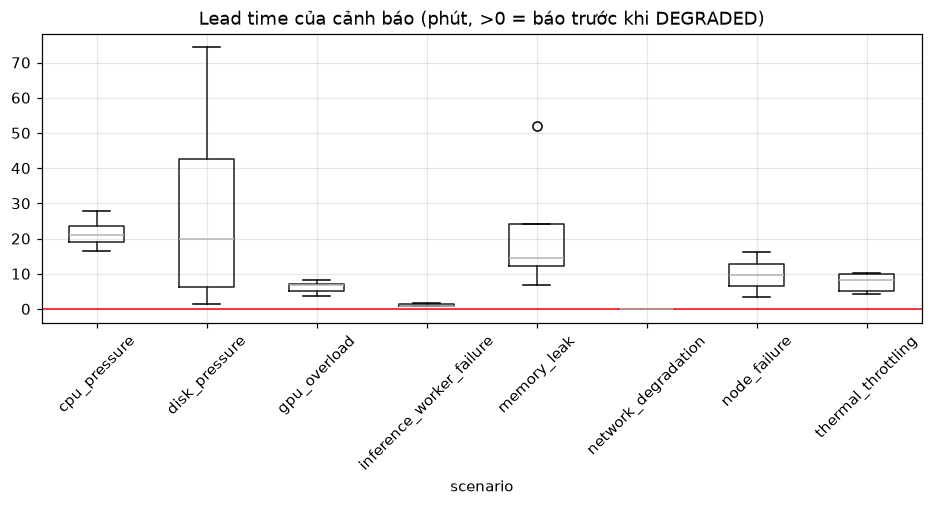

In [20]:
fig, ax = plt.subplots(figsize=(10, 3.5))
fail.dropna(subset=["lead_min"]).boxplot(column="lead_min", by="scenario", rot=45, ax=ax)
ax.axhline(0, color="r", lw=1); ax.set_title("Lead time của cảnh báo (phút, >0 = báo trước khi DEGRADED)"); plt.suptitle(""); plt.show()

### 9.4 Ví dụ trực quan: xác suất theo thời gian trên một episode lỗi

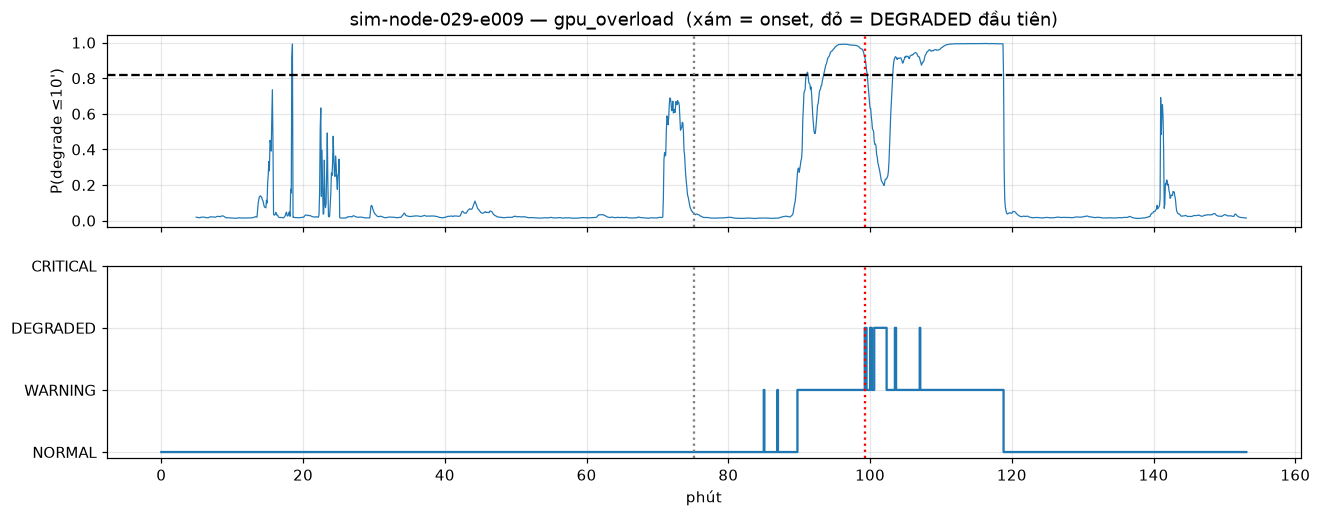

In [21]:
ex = fail.dropna(subset=["lead_min"]).sort_values("lead_min").episode.iloc[len(fail.dropna(subset=["lead_min"])) // 2]
x, state, _, sc = episode_matrix(DATA / "episodes" / f"{ex}.csv.gz", FEAT)
p = stream_probs(x); t = np.arange(len(p)) * 5 / 60
r = manifest.set_index("episode_id").loc[ex]
fig, ax = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
ax[0].plot(t, p, lw=0.8); ax[0].axhline(THR, color="k", ls="--"); ax[0].set_ylabel("P(degrade ≤10')")
ax[1].plot(t, state, drawstyle="steps-post"); ax[1].set_yticks(range(4), STATE_ORDER)
for a in ax:
    a.axvline(r.fault_onset_step * 5 / 60, color="gray", ls=":"); a.axvline(r.first_degraded_step * 5 / 60, color="r", ls=":")
ax[0].set_title(f"{ex} — {sc}  (xám = onset, đỏ = DEGRADED đầu tiên)"); ax[1].set_xlabel("phút"); plt.show()

### 9.5 Mức độ quan trọng của feature (permutation importance)

Xáo trộn một feature giữa các mẫu test (giữ nguyên chuỗi thời gian bên trong) và đo mức giảm PR-AUC.

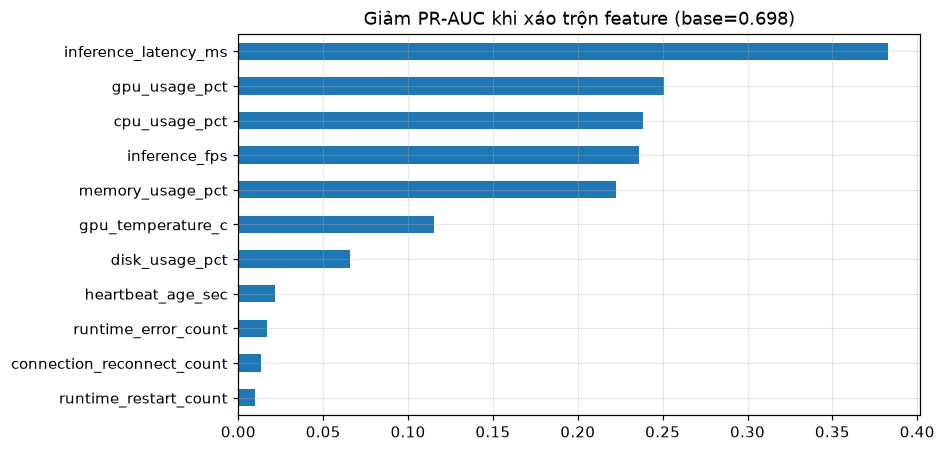

In [22]:
rng = np.random.default_rng(SEED); base_ap = average_precision_score(Y["test"], p_test); imp = {}
for j, f in enumerate(FEAT):
    xp = X["test"].copy(); xp[:, :, j] = xp[rng.permutation(len(xp)), :, j]
    imp[f] = base_ap - average_precision_score(Y["test"], predict(model, xp))
imp = pd.Series(imp).sort_values()
imp.plot.barh(figsize=(8, 4.5), title=f"Giảm PR-AUC khi xáo trộn feature (base={base_ap:.3f})"); plt.show()

## 10. Lưu model và metadata cho triển khai

In [23]:
artifact = {
    "state_dict": model.state_dict(), "config": CFG, "features": FEAT,
    "mean": MEAN.tolist(), "std": STD.tolist(), "counters_as_delta": COUNTERS,
    "window": int(d["window"]), "horizon": int(d["horizon"]), "sample_sec": 5,
    "threshold": THR, "alarm_consecutive": 3,
    "test": {"pr_auc": float(summary.loc["PR-AUC", "LSTM"]), "roc_auc": float(summary.loc["ROC-AUC", "LSTM"])},
}
torch.save(artifact, OUT / "node_health_lstm.pt")
hist.to_csv(OUT / "train_history.csv", index=False); per_sc.to_csv(OUT / "per_scenario_test.csv")
ops.to_csv(OUT / "ops_simulation_test.csv", index=False)
print("saved →", OUT)

saved → D:\Workspace\Research\ultralytics\app\dataset\telemetry_sim\models


### 10.1 Kích thước model và tốc độ inference

Đo trên thiết bị hiện tại (`DEVICE`). Batch 1 = độ trễ khi chấm 1 node mỗi chu kỳ 5 s; batch lớn = thông lượng khi chấm cả fleet cùng lúc.

In [24]:
n_params = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
size_mb = (OUT / "node_health_lstm.pt").stat().st_size / 1024 ** 2
w = int(d["window"])

@torch.no_grad()
def bench(batch, reps):
    model.eval(); x = torch.randn(batch, w, len(FEAT), device=DEVICE)
    for _ in range(10): model(x)  # warm-up
    if DEVICE == "cuda": torch.cuda.synchronize()
    t = []
    for _ in range(reps):
        t0 = time.perf_counter(); model(x)
        if DEVICE == "cuda": torch.cuda.synchronize()
        t.append(time.perf_counter() - t0)
    t = np.array(t) * 1000
    return dict(batch=batch, mean_ms=t.mean(), p50_ms=np.percentile(t, 50), p95_ms=np.percentile(t, 95),
                windows_per_sec=batch / (t.mean() / 1000))

bm = pd.DataFrame([bench(1, 500), bench(64, 200), bench(1024, 50)]).set_index("batch").round(3)
print(f"Thiết bị           : {DEVICE} ({torch.get_num_threads()} CPU threads)" if DEVICE == "cpu" else f"Thiết bị: {torch.cuda.get_device_name()}")
print(f"Số tham số         : {n_params:,} (trainable {n_train:,})")
print(f"Kích thước tham số : {n_params * 4 / 1024:.1f} KB (float32)")
print(f"File artifact .pt  : {size_mb * 1024:.1f} KB  ({OUT / 'node_health_lstm.pt'})")
print(f"Input mỗi mẫu      : {w} bước × {len(FEAT)} feature = {w * len(FEAT)} số")
display(bm)

Thiết bị           : cpu (12 CPU threads)
Số tham số         : 55,105 (trainable 55,105)
Kích thước tham số : 215.3 KB (float32)
File artifact .pt  : 222.1 KB  (D:\Workspace\Research\ultralytics\app\dataset\telemetry_sim\models\node_health_lstm.pt)
Input mỗi mẫu      : 60 bước × 11 feature = 660 số


,mean_ms,p50_ms,p95_ms,windows_per_sec
batch,,,,
1,9.144,3.628,28.087,109.359
64,94.909,35.864,219.303,674.329
1024,194.931,134.799,584.844,5253.129


## 11. Kết luận và hạn chế

- So sánh LSTM với baseline LogReg ở mục 8: nếu chênh lệch nhỏ, tín hiệu chủ yếu nằm ở xu hướng (slope/mean)
  mà thống kê cửa sổ đã bắt được; LSTM có lợi khi tín hiệu phụ thuộc thứ tự (ví dụ nhiệt tăng *rồi* FPS giảm).
- Lead time thực tế bị giới hạn bởi horizon 10 phút và bởi tốc độ tiến triển của lỗi (mục 4.5).
- **Hạn chế:** dữ liệu synthetic với thời gian ramp bị nén (lỗi chậm như leak/disk ngoài thực tế kéo dài
  giờ–ngày); chưa có kịch bản sập đột ngột không báo trước; nhãn dựa trên ngưỡng luật ở `labels.py`.
- **Bước tiếp:** validate trên telemetry thật từ Jetson; thêm horizon dài (1–6 giờ) hoặc hồi quy
  `time_to_degradation_sec`; so sánh với XGBoost (spec §24).